# FGM Prevalence, Kenya, all survey rounds (V2)

Same methodology as V1 (`V1/01_Notebooks/FGM_Prevalence_Incidence.ipynb`, DHS 2022 only)
applied to every Kenya DHS round: DHS 1998, 2003, 2008–09, 2014 and 2022 for women 15–49, and
the two full-roster rounds (DHS 2014, 2022) for daughters 0–14. Kenya has no national MICS;
its subnational MICS are compared in section 8A. Run `00_EDA_All_Rounds.ipynb` first.

- **Pooled data.** All rounds are analysed together. Direct estimates use one pooled
  survey design (each survey keeps its own clusters and strata), and the covariate-adjusted
  model is one survey-weighted BYM2 model on all rounds, with a survey-round term absorbing
  level differences between rounds. Maps show the pooled estimates for the 8 former provinces
  and, as in V1, estimates by birth cohort; section 8B adds county estimates (47 counties) from
  DHS 2014 and 2022.
- **Covariates not collected in a round** (wealth in DHS 1998) are kept as
  an "unknown" category, so no round is dropped.
- **Trends by survey year** (section 7) are the only outputs shown by round.
- **Definitions.** Never-heard women and their daughters are counted as not cut (DHS
  convention); women with a missing status are excluded. DHS 2014 and 2022 asked the FGM
  questions only in the long-questionnaire subsample.

## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"

project_root <- if (dir.exists("../02_Data")) ".." else "."
analysis_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "analysis")
output_dir <- file.path(project_root, "03_Outputs", country_iso3, "Prevalence")
dirs <- list(
  direct = file.path(output_dir, "01_Direct_and_Smoothed"),
  maps = file.path(output_dir, "02_Prevalence_Maps"),
  adjusted = file.path(output_dir, "03_Covariate_Adjusted"),
  cohort = file.path(output_dir, "04_Birth_Cohort"),
  trends = file.path(output_dir, "05_Trends"),
  validation = file.path(output_dir, "06_Validation")
)
for (d in dirs) dir.create(d, recursive = TRUE, showWarnings = FALSE)

shapefile_path <- file.path(project_root, "02_Data", "processed", "KEN", "boundaries", "KEN_provinces.shp")
region_var_shapefile <- "PROVINCE"
# Region keys as in the harmonized data: upper case, hyphens as spaces ("CENTRE EST").
standardize_region <- function(x) toupper(as.character(x)) |> stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()
posterior_draws <- 200L
minimum_cohort_cell_n <- 10L
run_spatial_model <- file.exists(shapefile_path)

options(repr.plot.width = 14, repr.plot.height = 9, width = 200)
cat("Configured for:", country_name, "| outputs:", normalizePath(output_dir, mustWork = FALSE), "\n")

Configured for: Kenya | outputs: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/V2/03_Outputs/KEN/Prevalence 


## 1. Setup and packages

In [2]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(survey)
  library(sf)
  library(spdep)
  library(INLA)
})
options(survey.lonely.psu = "adjust")
set.seed(20260101)

## 2. Load the prevalence data

In [3]:
round_order <- c("DHS 1998", "DHS 2003", "DHS 2008", "DHS 2014", "DHS 2022")
women <- readRDS(file.path(analysis_dir, paste0(country_iso3, "_prevalence_self.rds"))) |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_order))
daughters <- readRDS(file.path(analysis_dir, paste0(country_iso3, "_prevalence_daughter.rds"))) |>
  dplyr::mutate(survey_id = factor(survey_id, levels = round_order))
survey_years <- women |> dplyr::distinct(survey_id, survey_type, round_year)

IRdisplay::display(as.data.frame(dplyr::full_join(
  women |> dplyr::count(survey_id, name = "women_15_49"),
  daughters |> dplyr::count(survey_id, name = "daughters_0_14"), by = "survey_id") |> dplyr::arrange(survey_id)))

survey_id,women_15_49,daughters_0_14
<fct>,<int>,<int>
DHS 1998,7873,NA
DHS 2003,8174,NA
DHS 2008,8433,NA
DHS 2014,14734,13189
DHS 2022,16902,13525


## 3. Design-based direct estimates, by region (pooled)

One pooled survey design across all rounds; each survey keeps its own clusters and strata.
Daughters inherit their mother's design variables. National estimates by survey round are
kept for the trend in section 7.

Shared functions: pooled model, pooled direct estimates and map layouts.

In [4]:
# Pooled survey-weighted BYM2 model on all survey rounds together. Weights are mean-one
# within each survey, so every round contributes in proportion to its sample size; a
# survey-round term absorbs level differences between rounds. Covariates a round did not
# collect are kept as an "unknown" category so no round is dropped. Respondents with
# identical predictors and outcome are grouped with summed weights, which leaves the
# weighted likelihood unchanged.
prepare_pooled <- function(data, outcome, covariates) {
  data |>
    dplyr::filter(!is.na(.data[[outcome]]), is.finite(weight), weight > 0, is.finite(age),
                  !is.na(birth_cohort), region %in% region_keys) |>
    dplyr::mutate(region_id = match(region, region_keys),
                  dplyr::across(dplyr::all_of(covariates), ~ factor(tidyr::replace_na(as.character(.x), "unknown"))),
                  survey_id = factor(as.character(survey_id)),
                  birth_cohort = as.character(birth_cohort),
                  age_id = as.integer(age - min(age) + 1L)) |>
    dplyr::group_by(dplyr::across(dplyr::all_of(c("region", "region_id", "age_id", "birth_cohort", "survey_id",
                                                  covariates, outcome)))) |>
    dplyr::summarise(survey_weight = sum(weight), n = dplyr::n(), .groups = "drop")
}

fit_pooled <- function(grouped, outcome, covariates, spatial_only = FALSE, n_draws = posterior_draws, seed = 1L) {
  fixed <- if (spatial_only) "1" else paste(c("survey_id", covariates), collapse = " + ")
  age_term <- if (spatial_only) "" else " + f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE)"
  model_formula <- stats::as.formula(paste0(outcome, " ~ ", fixed, age_term,
    " + f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"))
  fit <- INLA::inla(model_formula, family = "binomial", data = grouped, Ntrials = rep(1L, nrow(grouped)),
                    weights = grouped$survey_weight,
                    control.predictor = list(compute = TRUE, link = 1),
                    control.compute = list(config = TRUE, dic = TRUE, waic = TRUE),
                    control.inla = list(control.vb = list(enable = FALSE)),
                    # Weakly informative N(0, sd 2) prior on the fixed effects (Kenya): groups with
                    # almost no cases (e.g. Kikuyu girls) otherwise give unbounded coefficients and
                    # inflated, unstable predictions in low-prevalence provinces.
                    control.fixed = list(prec = 0.25, prec.intercept = 0.001))
  set.seed(seed)
  samples <- INLA::inla.posterior.sample(n_draws, fit, use.improved.mean = FALSE, skew.corr = FALSE)
  rows <- grep("^Predictor:", rownames(samples[[1]]$latent))
  rows <- rows[order(as.integer(sub("^Predictor:", "", rownames(samples[[1]]$latent)[rows])))]
  stopifnot(length(rows) == nrow(grouped))
  w <- grouped$survey_weight
  weighted_probs <- lapply(samples, function(s) stats::plogis(as.numeric(s$latent[rows, 1L])) * w)
  rm(samples)
  groupings <- list(
    state = grouped$region,
    state_cohort = paste(grouped$region, grouped$birth_cohort, sep = "|"),
    cohort = grouped$birth_cohort,
    survey = as.character(grouped$survey_id),
    national = rep(country_name, nrow(grouped))
  )
  summaries <- lapply(groupings, function(g) {
    g <- factor(g)
    num <- vapply(weighted_probs, function(pw) as.numeric(rowsum(pw, g)), numeric(nlevels(g)))
    if (is.null(dim(num))) num <- matrix(num, nrow = nlevels(g))
    den <- as.numeric(rowsum(w, g))
    est <- num / den
    tibble::tibble(group = levels(g), estimate = rowMeans(est),
                   lower_ci = apply(est, 1, stats::quantile, 0.025, names = FALSE),
                   upper_ci = apply(est, 1, stats::quantile, 0.975, names = FALSE),
                   n_unweighted = as.numeric(rowsum(grouped$n, g)), sum_weight = den)
  })
  list(fit = fit, state = summaries$state |> dplyr::rename(region = group),
       state_cohort = summaries$state_cohort |> tidyr::separate(group, c("region", "birth_cohort"), sep = "\\|"),
       cohort = summaries$cohort |> dplyr::rename(birth_cohort = group),
       survey = summaries$survey |> dplyr::rename(survey_id = group),
       national = summaries$national |> dplyr::select(-group),
       fixed = tibble::as_tibble(fit$summary.fixed, rownames = "term"),
       residual = tibble::tibble(region = region_keys,
                                 residual_effect = fit$summary.random$region_id$mean[seq_along(region_keys)]),
       fit_stats = tibble::tibble(dic = fit$dic$dic, waic = fit$waic$waic, rows = nrow(grouped),
                                  respondents = sum(grouped$n)))
}

# Pooled design-based direct estimate by a grouping variable (each survey keeps its own
# clusters and strata inside the pooled design).
pooled_direct <- function(data, outcome, by) {
  d <- data |> dplyr::filter(!is.na(.data[[outcome]]))
  design <- survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~weight, data = d, nest = TRUE)
  est <- survey::svyby(stats::as.formula(paste0("~", outcome)), stats::as.formula(paste0("~", by)), design, survey::svymean)
  tibble::tibble(!!by := est[[by]], direct = as.numeric(est[[outcome]]), se = as.numeric(est$se)) |>
    dplyr::mutate(lower_ci = pmax(direct - 1.96 * se, 0), upper_ci = pmin(direct + 1.96 * se, 1),
                  n = as.integer(table(d[[by]])[as.character(.data[[by]])]))
}

# One map per estimate set (V1 style) and a faceted birth-cohort map.
state_map <- function(estimates, value_col, title_text, subtitle_text, legend_title, fill_limits) {
  map_data <- boundaries |> dplyr::mutate(region = region_keys) |> dplyr::left_join(estimates, by = "region")
  ggplot2::ggplot(map_data) +
    ggplot2::geom_sf(ggplot2::aes(fill = .data[[value_col]]), color = "grey40", linewidth = 0.15) +
    ggplot2::scale_fill_viridis_c(name = legend_title, option = "magma", direction = -1,
                                  labels = scales::percent_format(accuracy = 1), limits = fill_limits,
                                  oob = scales::squish, na.value = "grey90") +
    ggplot2::coord_sf(datum = sf::st_crs(4326)) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = "Longitude", y = "Latitude") +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
                   axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8))
}
cohort_map <- function(estimates, value_col, title_text, subtitle_text, legend_title, fill_limits) {
  map_data <- boundaries |> dplyr::mutate(region = region_keys) |>
    dplyr::left_join(estimates, by = "region", relationship = "one-to-many") |> dplyr::filter(!is.na(birth_cohort))
  ggplot2::ggplot() +
    ggplot2::geom_sf(data = boundaries, fill = "grey90", color = "grey60", linewidth = 0.1) +
    ggplot2::geom_sf(data = map_data, ggplot2::aes(fill = .data[[value_col]]), color = "grey40", linewidth = 0.12) +
    ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
    ggplot2::scale_fill_viridis_c(name = legend_title, option = "magma", direction = -1,
                                  labels = scales::percent_format(accuracy = 1), limits = fill_limits, oob = scales::squish) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = NULL, y = NULL) +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 16, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   strip.text = ggplot2::element_text(face = "bold", size = 10),
                   strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
                   axis.text = ggplot2::element_blank(), axis.ticks = ggplot2::element_blank())
}
residual_map <- function(residuals, title_text, subtitle_text) {
  lim <- max(abs(residuals$residual_effect), na.rm = TRUE)
  ggplot2::ggplot(boundaries |> dplyr::mutate(region = region_keys) |> dplyr::left_join(residuals, by = "region")) +
    ggplot2::geom_sf(ggplot2::aes(fill = residual_effect), color = "grey40", linewidth = 0.15) +
    ggplot2::scale_fill_gradient2(name = "Residual\nlog-odds", low = "#1D4E89", mid = "white", high = "#D9534F",
                                  midpoint = 0, limits = c(-lim, lim)) +
    ggplot2::labs(title = title_text, subtitle = subtitle_text, x = "Longitude", y = "Latitude") +
    ggplot2::theme_bw(base_size = 12) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                   axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8))
}

In [5]:
direct_self <- pooled_direct(women, "fgm_self", "region")
direct_daughter <- pooled_direct(daughters, "fgm_daughter", "region")
national_direct <- dplyr::bind_rows(
  pooled_direct(women, "fgm_self", "survey_id") |> dplyr::mutate(population = "Women 15-49"),
  pooled_direct(daughters, "fgm_daughter", "survey_id") |> dplyr::mutate(population = "Girls 0-14")) |>
  dplyr::mutate(survey_id = as.character(survey_id))
readr::write_csv(direct_self, file.path(dirs$direct, paste0(country_iso3, "_prevalence_direct_by_region_self.csv")))
readr::write_csv(direct_daughter, file.path(dirs$direct, paste0(country_iso3, "_prevalence_direct_by_region_daughter.csv")))
readr::write_csv(national_direct, file.path(dirs$direct, paste0(country_iso3, "_prevalence_direct_national_by_round.csv")))
cat("Pooled direct estimates:", nrow(direct_self), "regions (women),", nrow(direct_daughter), "regions (girls)\n")

Pooled direct estimates: 8 regions (women), 8 regions (girls)


## 4. BYM2 spatial smoothing (pooled)

V1 architecture on the pooled direct estimates: logit-scale region-adjacency BYM2 via INLA,
each estimate weighted by its sampling precision (capped at 1e6). Penalised-complexity
priors and explicit starting values are used for the BYM2 parameters, because INLA's default
settings intermittently failed to converge on this model.

In [6]:
boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
region_keys <- standardize_region(boundaries[[region_var_shapefile]])
adjacency <- spdep::poly2nb(boundaries, row.names = region_keys)
adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)
stopifnot(all(unique(c(women$region, daughters$region)) %in% region_keys))

fit_bym2_prevalence <- function(direct_estimates) {
  eps <- 1e-4
  d <- direct_estimates |>
    dplyr::mutate(region_id = match(region, region_keys), p = pmin(pmax(direct, eps), 1 - eps),
                  se_p = pmax(se, eps), logit_est = qlogis(p), logit_prec = pmin(((p * (1 - p))^2) / (se_p^2), 1e6))
  # Penalised-complexity priors and explicit starting values keep INLA's optimizer stable
  # on this small 13-region model (default priors can fail to converge).
  bym2_hyper <- list(prec = list(prior = "pc.prec", param = c(1, 0.01)), phi = list(prior = "pc", param = c(0.5, 2 / 3)))
  fit_once <- function(control_inla) INLA::inla(
    logit_est ~ f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE, hyper = bym2_hyper),
    family = "gaussian", data = d, scale = d$logit_prec,
    control.family = list(hyper = list(prec = list(fixed = TRUE, initial = 0))),
    control.predictor = list(compute = TRUE), control.mode = list(theta = c(0, 0), restart = TRUE),
    control.inla = control_inla, num.threads = "1:1")
  # INLA's optimizer intermittently fails to converge on the first calls of a session;
  # retry, alternating default and stabilised settings (cmin = 0, empirical Bayes).
  settings <- list(list(), list(cmin = 0, int.strategy = "eb"), list(), list(cmin = 0, int.strategy = "eb"))
  model <- NULL
  for (k in seq_along(settings)) {
    model <- tryCatch(fit_once(settings[[k]]), error = function(e) NULL)
    if (!is.null(model)) break
    message("BYM2 smoothing: attempt ", k, " did not converge, retrying")
  }
  if (is.null(model)) stop("BYM2 smoothing failed after ", length(settings), " attempts")
  d |> dplyr::mutate(smoothed_prevalence = plogis(model$summary.fitted.values$mean),
                     smoothed_lower = plogis(model$summary.fitted.values$`0.025quant`),
                     smoothed_upper = plogis(model$summary.fitted.values$`0.975quant`))
}
smoothed_self <- fit_bym2_prevalence(direct_self)
smoothed_daughter <- fit_bym2_prevalence(direct_daughter)
readr::write_csv(smoothed_self, file.path(dirs$direct, paste0(country_iso3, "_prevalence_smoothed_by_region_self.csv")))
readr::write_csv(smoothed_daughter, file.path(dirs$direct, paste0(country_iso3, "_prevalence_smoothed_by_region_daughter.csv")))

## 5. Prevalence maps (pooled)

Smoothed region prevalence pooling all rounds, on one scale for women and girls.

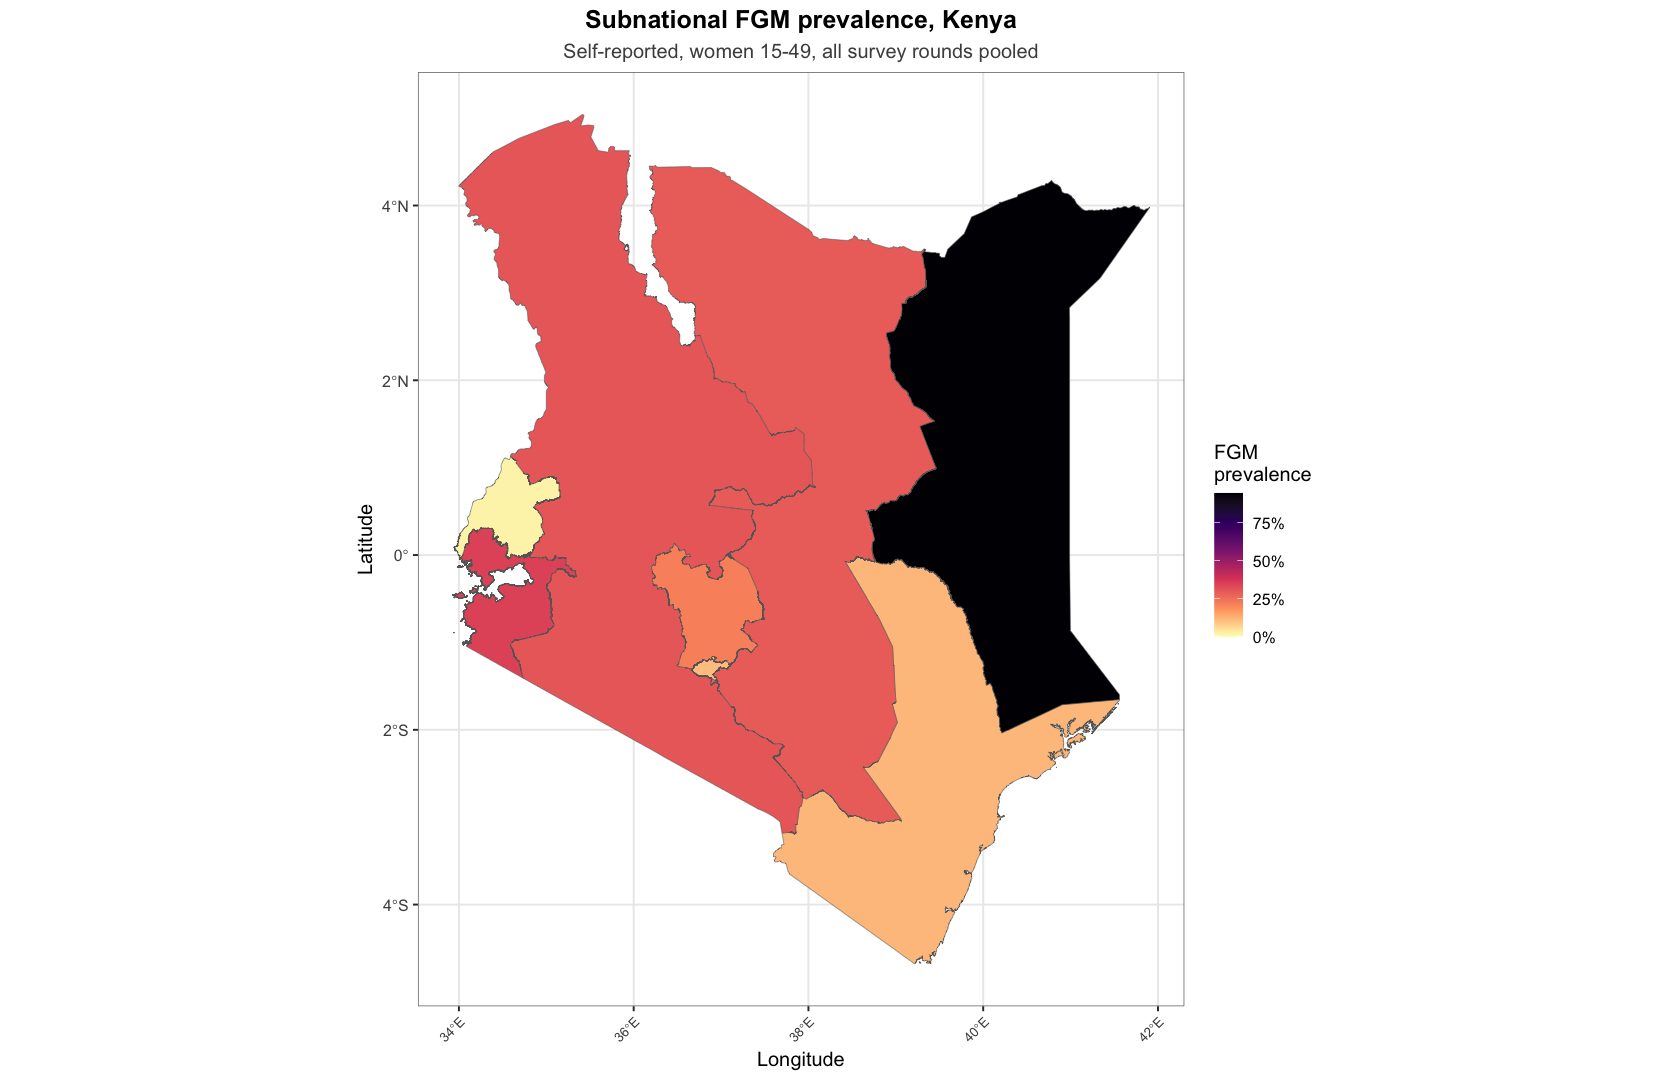

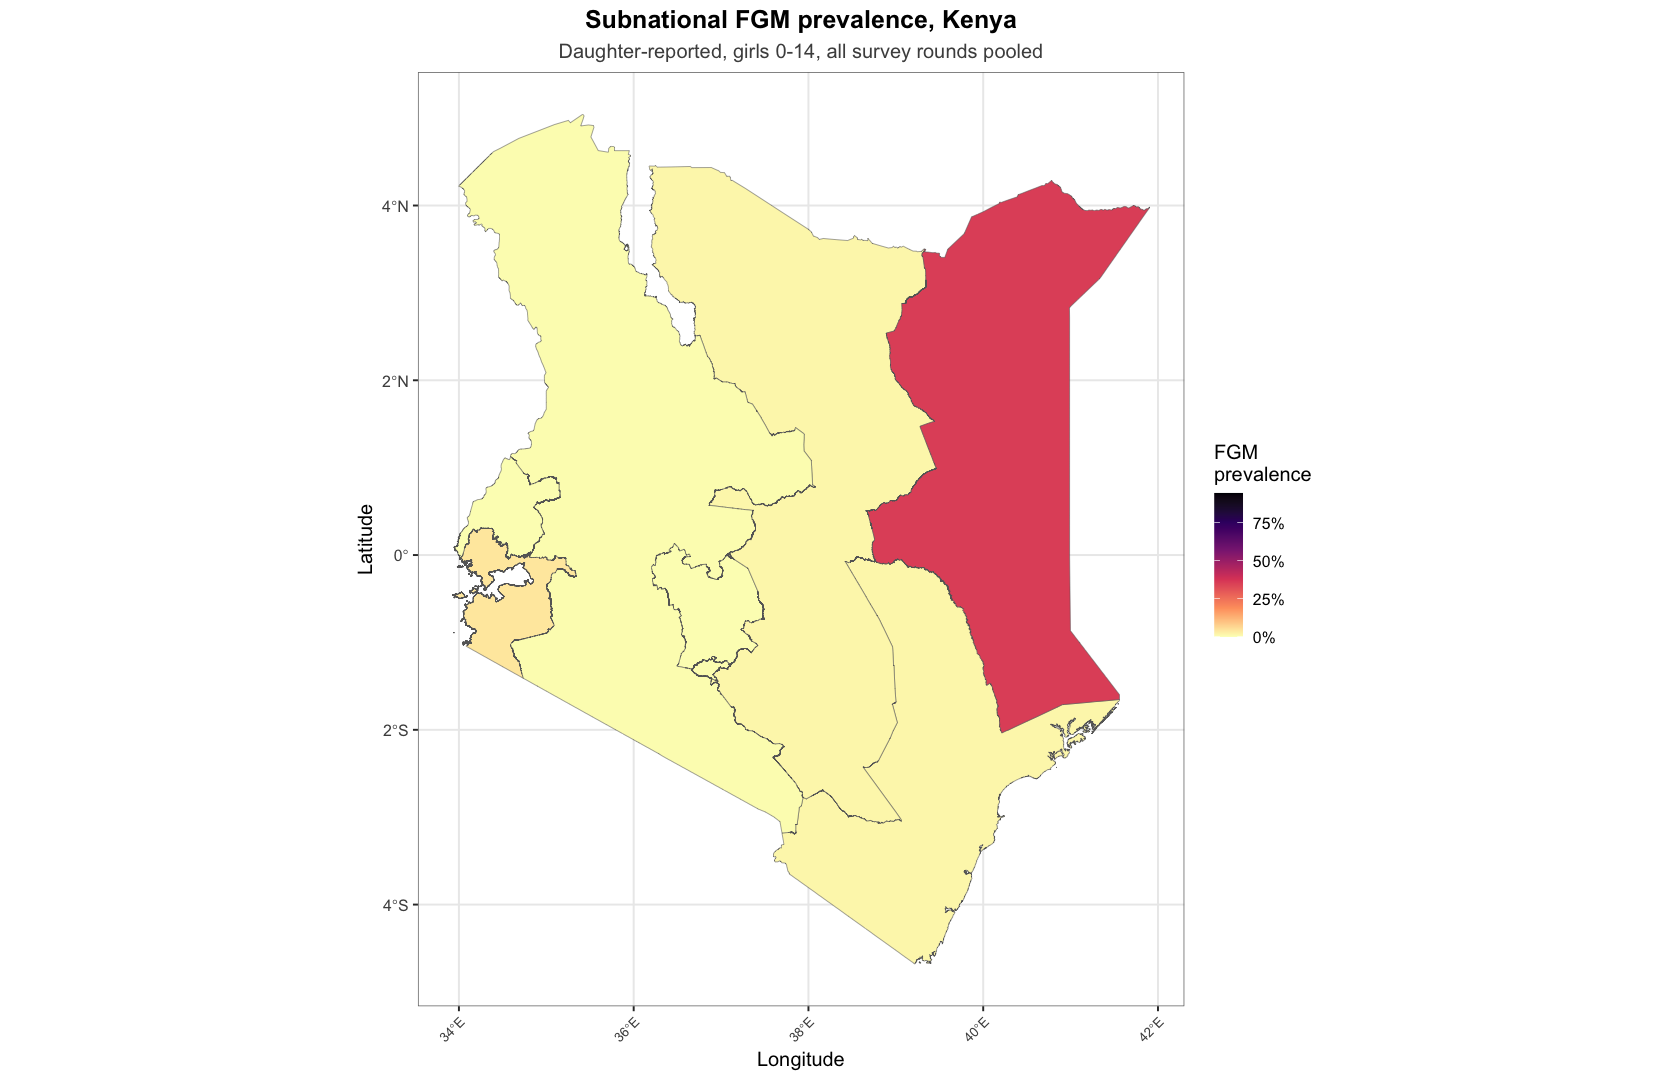

In [7]:
fill_limits <- c(0, max(smoothed_self$smoothed_prevalence, smoothed_daughter$smoothed_prevalence))
self_prevalence_map <- state_map(smoothed_self, "smoothed_prevalence", paste("Subnational FGM prevalence,", country_name),
                                 "Self-reported, women 15-49, all survey rounds pooled", "FGM\nprevalence", fill_limits)
daughter_prevalence_map <- state_map(smoothed_daughter, "smoothed_prevalence", paste("Subnational FGM prevalence,", country_name),
                                     "Daughter-reported, girls 0-14, all survey rounds pooled", "FGM\nprevalence", fill_limits)
print(self_prevalence_map); print(daughter_prevalence_map)
ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_prevalence_map_self.png")), self_prevalence_map, width = 9, height = 8, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_prevalence_map_daughter.png")), daughter_prevalence_map, width = 9, height = 8, dpi = 300, bg = "white")

## 6. Survey-weighted covariate-adjusted spatial prevalence model (pooled)

V1 model fitted once to all rounds for each population: unit-level binomial with normalized
survey weights, ethnicity, wealth, education, religion and urban/rural as fixed effects,
age as RW2, region as BYM2, plus a survey-round term. For each posterior draw, fitted
probabilities are averaged with the survey weights within region, region × birth cohort, birth
cohort, survey round and nationally. Intervals are pseudo-posterior, not fully design-based.

In [8]:
prevalence_covariates <- c("ethnicity", "wealth", "education", "religion", "urban_rural")
t0 <- Sys.time()
model_self <- fit_pooled(prepare_pooled(women, "fgm_self", prevalence_covariates), "fgm_self", prevalence_covariates, seed = 2026L)
model_daughter <- fit_pooled(prepare_pooled(daughters, "fgm_daughter", prevalence_covariates), "fgm_daughter", prevalence_covariates, seed = 2027L)
cat("Pooled models fitted in", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), "min\n")
IRdisplay::display(as.data.frame(dplyr::bind_rows(model_self$fit_stats |> dplyr::mutate(population = "Women 15-49"),
                                                  model_daughter$fit_stats |> dplyr::mutate(population = "Girls 0-14"))))
fixed_effects <- dplyr::bind_rows(model_self$fixed |> dplyr::mutate(population = "Women 15-49"),
                                  model_daughter$fixed |> dplyr::mutate(population = "Girls 0-14"))
readr::write_csv(fixed_effects, file.path(dirs$adjusted, paste0(country_iso3, "_prevalence_model_fixed_effects.csv")))

Pooled models fitted in 0.2 min


dic,waic,rows,respondents,population
<dbl>,<dbl>,<int>,<int>,<chr>
30850.008,30966.902,30201,56116,Women 15-49
2025.331,2056.969,10339,26714,Girls 0-14


### 6.1 Model-assisted region prevalence (pooled)

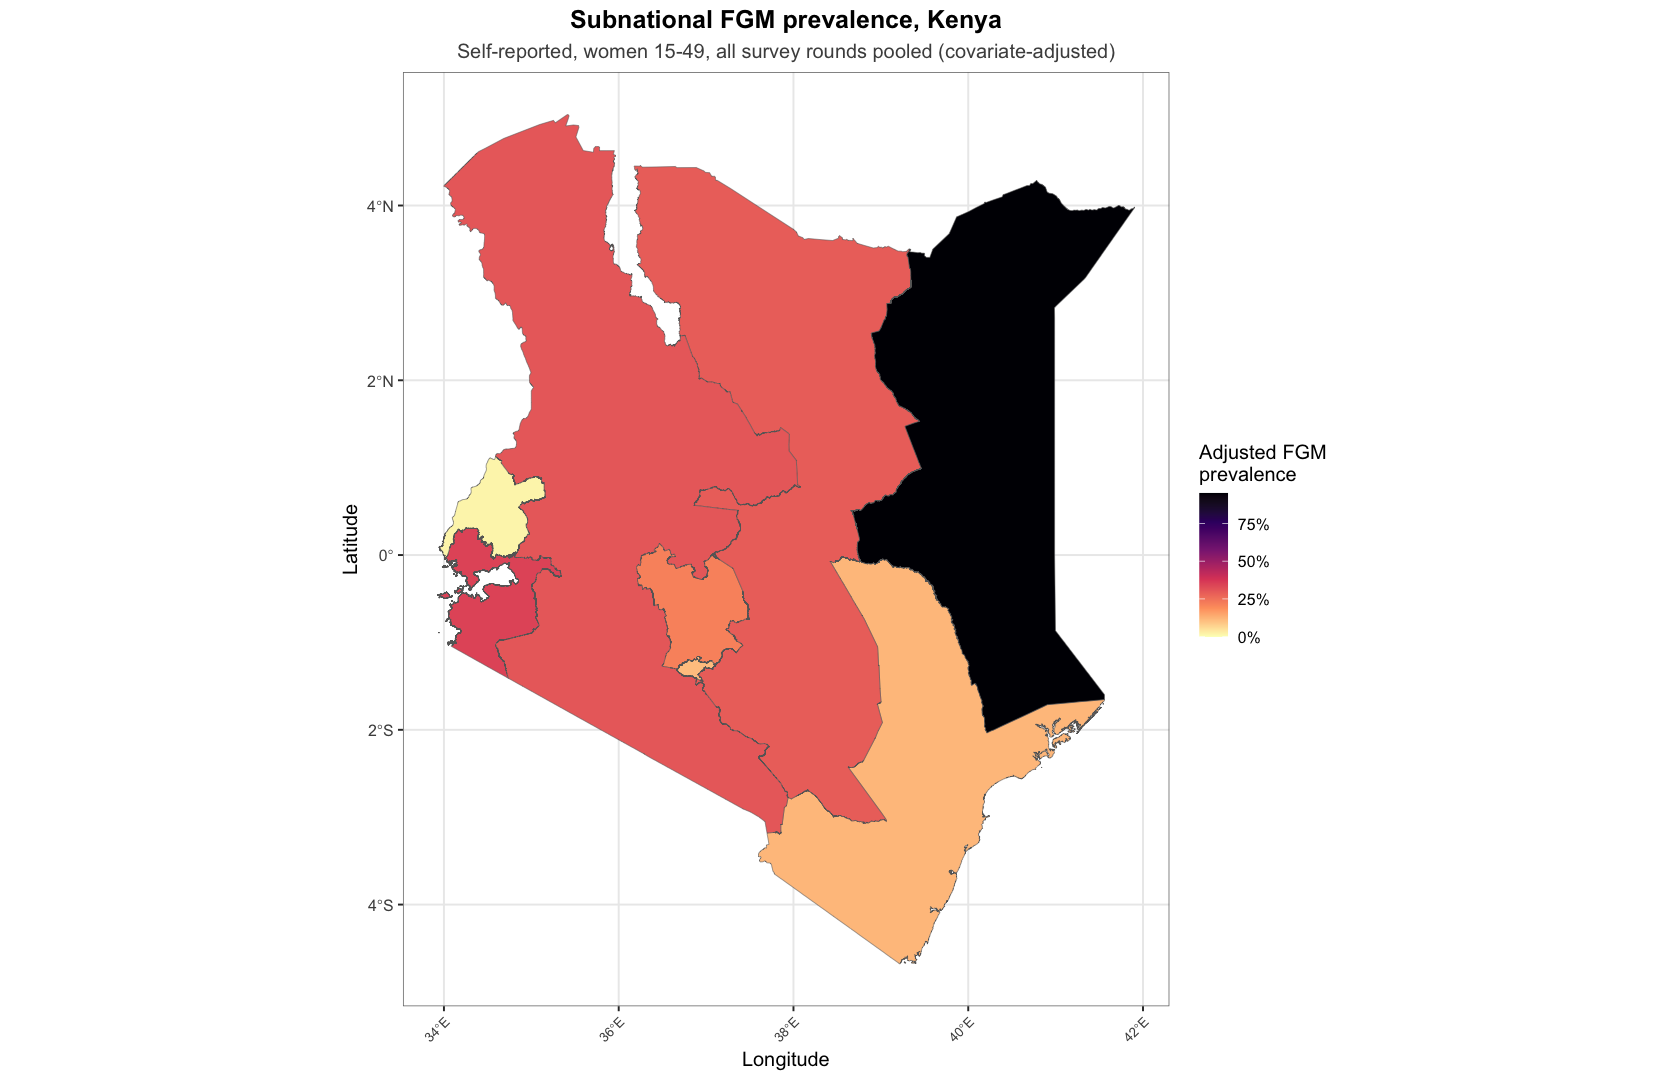

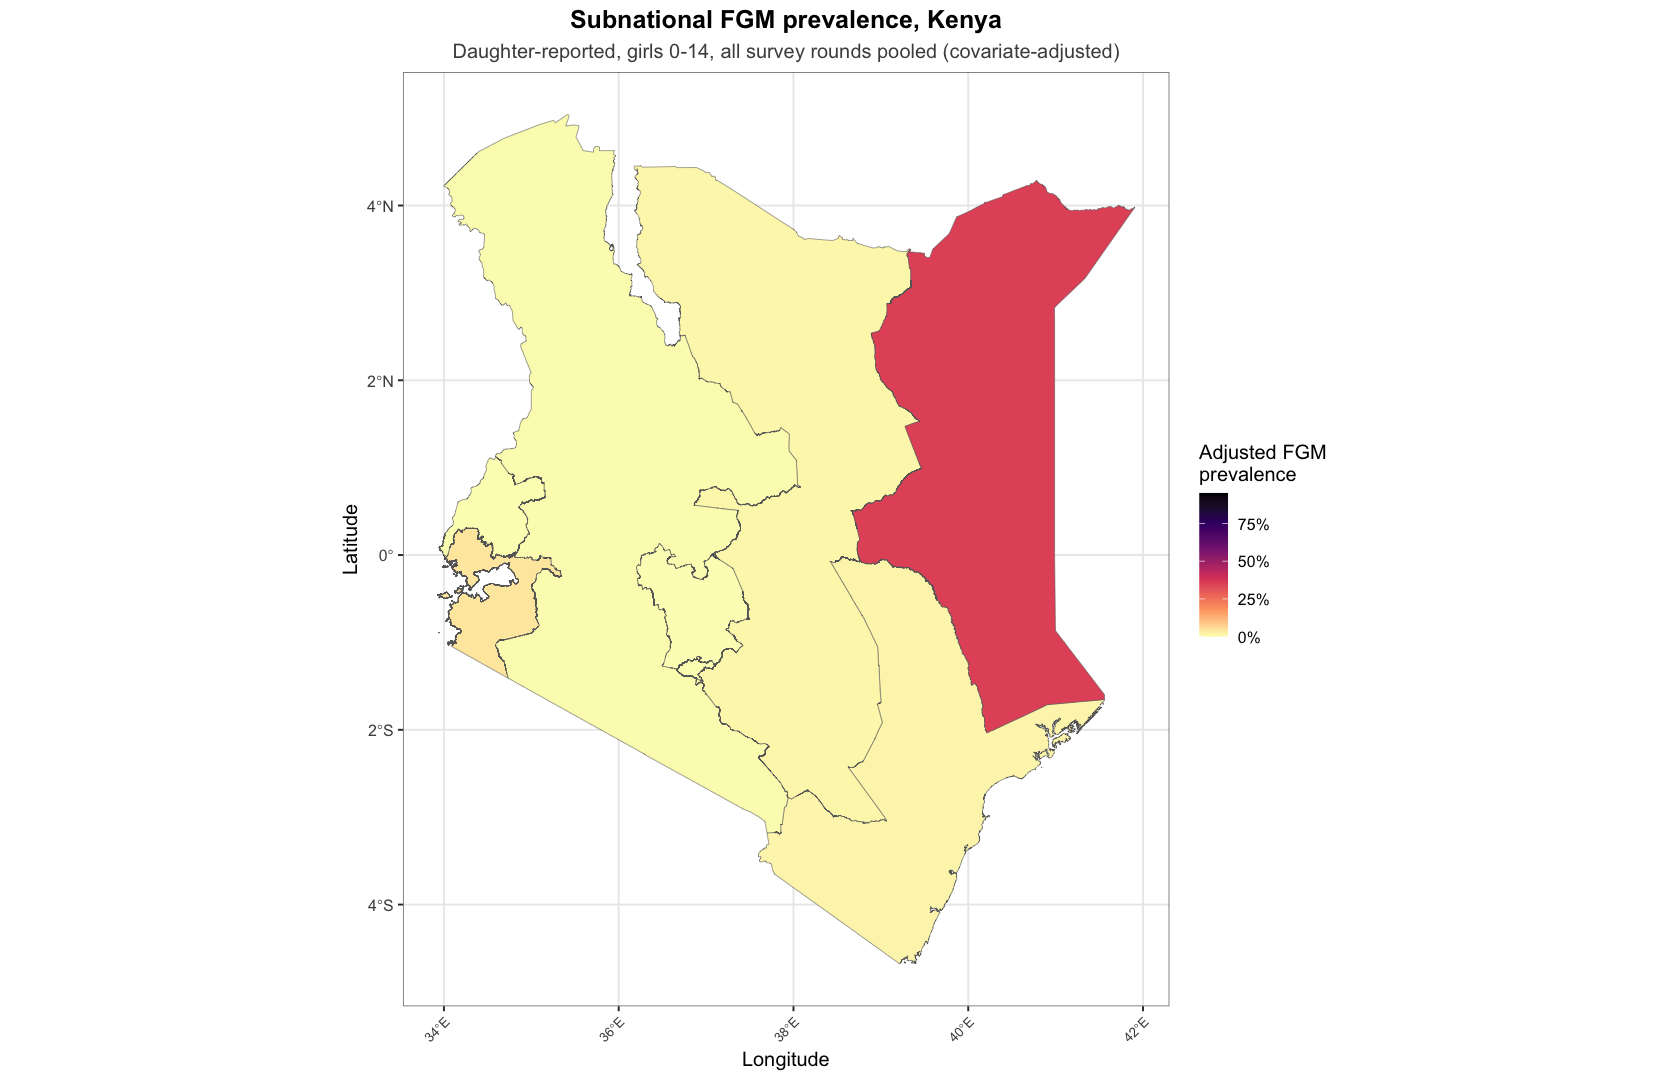

In [9]:
adjusted_self <- model_self$state |> dplyr::rename(model_assisted_prevalence = estimate) |>
  dplyr::left_join(direct_self |> dplyr::select(region, design_based_direct = direct), by = "region")
adjusted_daughter <- model_daughter$state |> dplyr::rename(model_assisted_prevalence = estimate) |>
  dplyr::left_join(direct_daughter |> dplyr::select(region, design_based_direct = direct), by = "region")
readr::write_csv(adjusted_self, file.path(dirs$adjusted, paste0(country_iso3, "_prevalence_covariate_adjusted_self.csv")))
readr::write_csv(adjusted_daughter, file.path(dirs$adjusted, paste0(country_iso3, "_prevalence_covariate_adjusted_daughter.csv")))

adjusted_fill <- c(0, max(adjusted_self$model_assisted_prevalence, adjusted_daughter$model_assisted_prevalence))
adjusted_self_map <- state_map(adjusted_self, "model_assisted_prevalence", paste("Subnational FGM prevalence,", country_name),
                               "Self-reported, women 15-49, all survey rounds pooled (covariate-adjusted)", "Adjusted FGM\nprevalence", adjusted_fill)
adjusted_daughter_map <- state_map(adjusted_daughter, "model_assisted_prevalence", paste("Subnational FGM prevalence,", country_name),
                                   "Daughter-reported, girls 0-14, all survey rounds pooled (covariate-adjusted)", "Adjusted FGM\nprevalence", adjusted_fill)
print(adjusted_self_map); print(adjusted_daughter_map)
ggplot2::ggsave(file.path(dirs$adjusted, paste0(country_iso3, "_prevalence_covariate_adjusted_map_self.png")), adjusted_self_map, width = 9, height = 8, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(dirs$adjusted, paste0(country_iso3, "_prevalence_covariate_adjusted_map_daughter.png")), adjusted_daughter_map, width = 9, height = 8, dpi = 300, bg = "white")

### 6.1A Covariate-adjusted prevalence by birth cohort (pooled)

As in V1, the same fitted model aggregated within region × five-year birth cohort, pooling
every round in which a cohort appears. Cells with fewer than 10 respondents are suppressed.

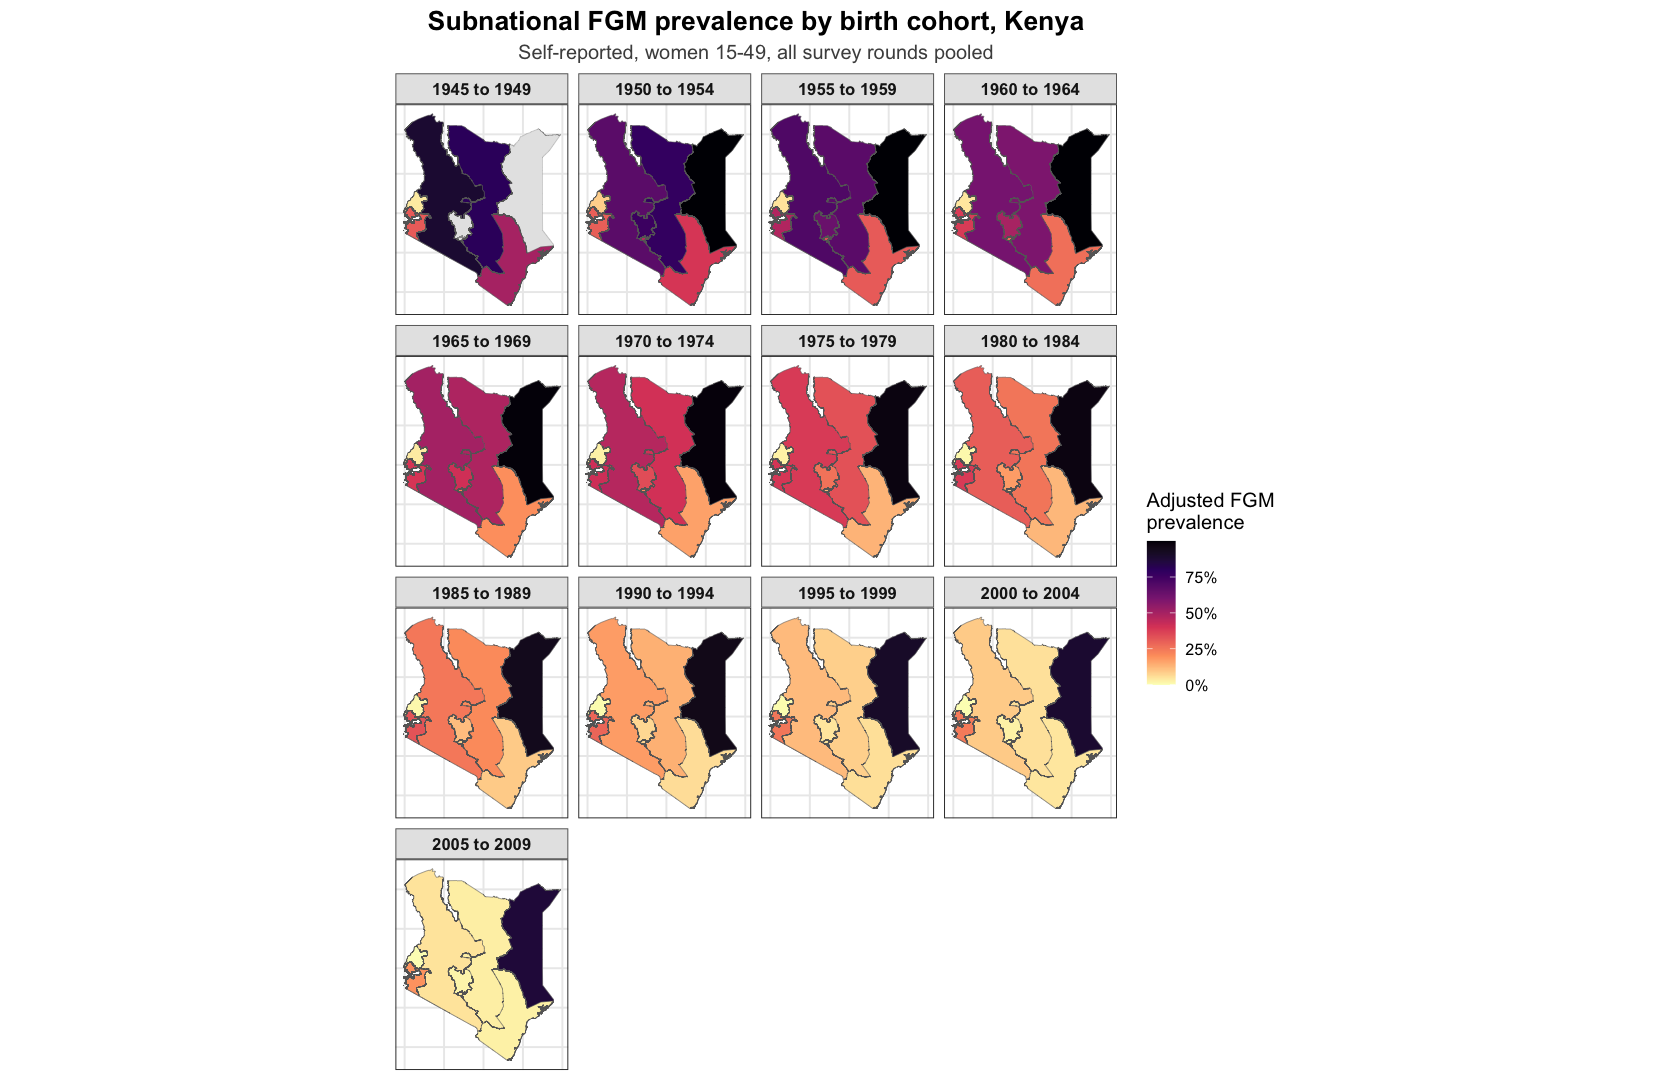

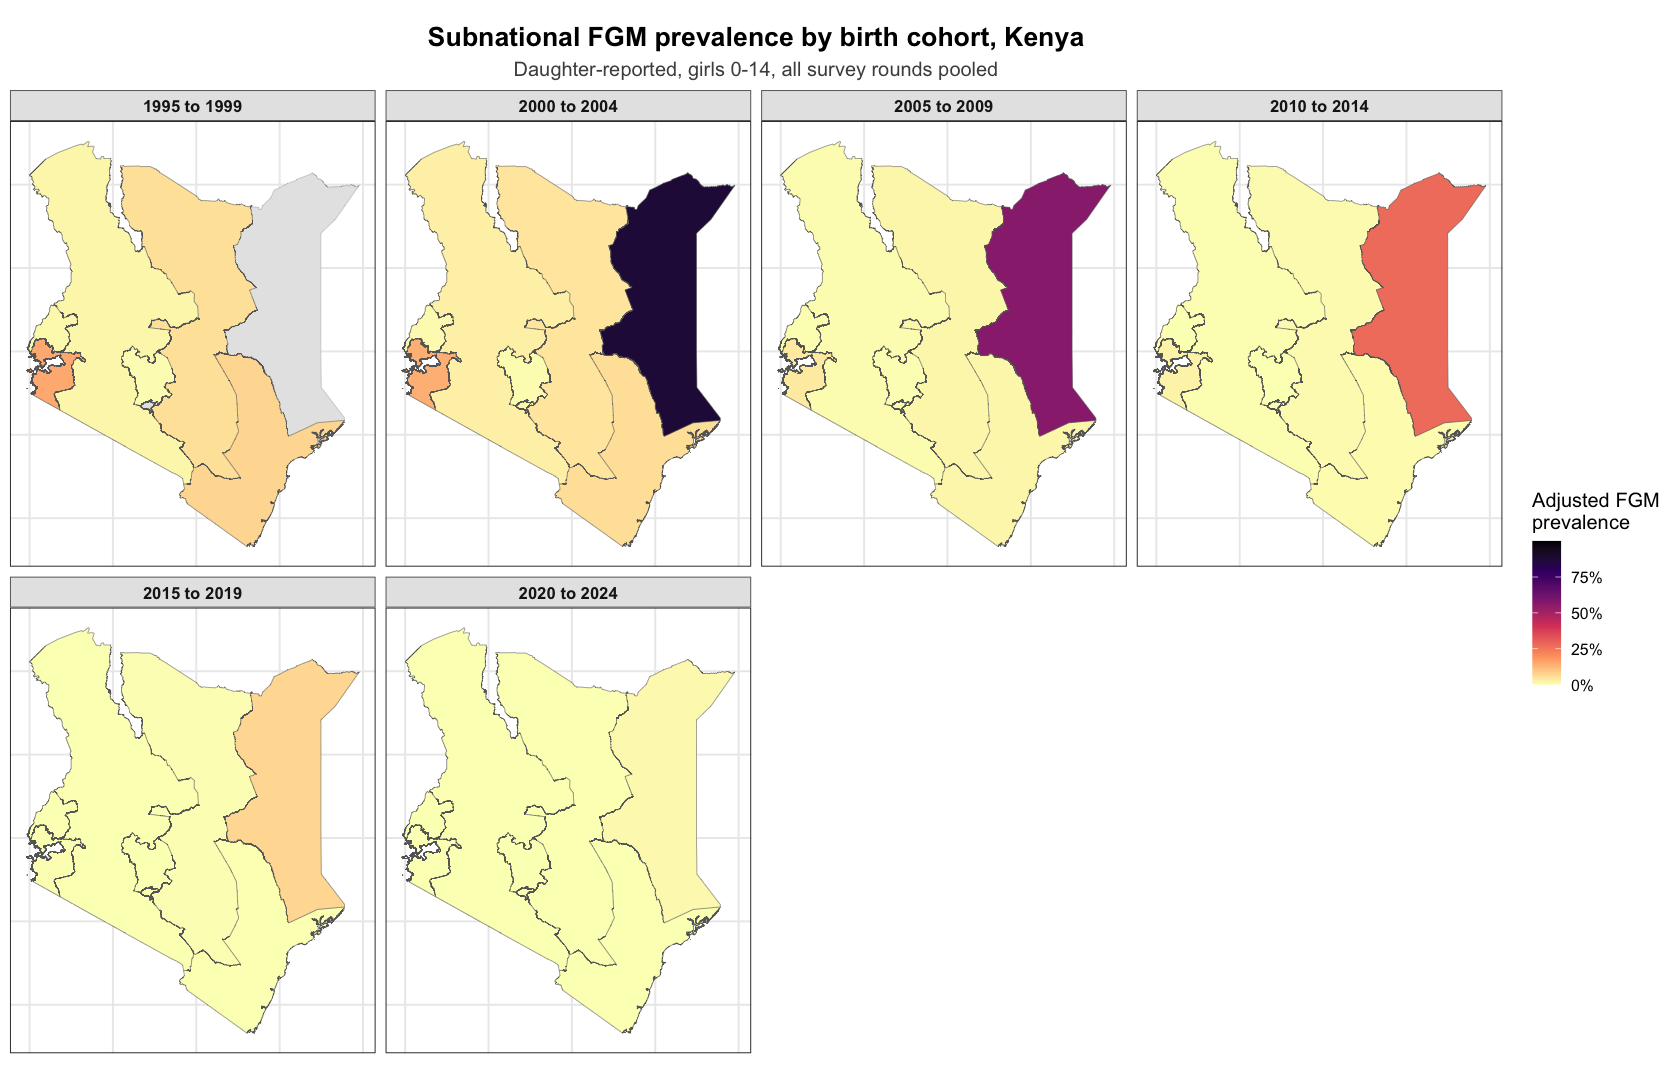

In [10]:
cohort_cells <- function(m) m$state_cohort |> dplyr::filter(n_unweighted >= minimum_cohort_cell_n) |>
  dplyr::rename(model_assisted_prevalence = estimate)
adjusted_self_cohort <- cohort_cells(model_self)
adjusted_daughter_cohort <- cohort_cells(model_daughter)
readr::write_csv(adjusted_self_cohort, file.path(dirs$cohort, paste0(country_iso3, "_prevalence_covariate_adjusted_by_cohort_self.csv")))
readr::write_csv(adjusted_daughter_cohort, file.path(dirs$cohort, paste0(country_iso3, "_prevalence_covariate_adjusted_by_cohort_daughter.csv")))
cohort_fill <- c(0, max(adjusted_self_cohort$model_assisted_prevalence, adjusted_daughter_cohort$model_assisted_prevalence))
self_cohort_map <- cohort_map(adjusted_self_cohort, "model_assisted_prevalence",
  paste("Subnational FGM prevalence by birth cohort,", country_name), "Self-reported, women 15-49, all survey rounds pooled",
  "Adjusted FGM\nprevalence", cohort_fill)
daughter_cohort_map <- cohort_map(adjusted_daughter_cohort, "model_assisted_prevalence",
  paste("Subnational FGM prevalence by birth cohort,", country_name), "Daughter-reported, girls 0-14, all survey rounds pooled",
  "Adjusted FGM\nprevalence", cohort_fill)
print(self_cohort_map); print(daughter_cohort_map)
ggplot2::ggsave(file.path(dirs$cohort, paste0(country_iso3, "_prevalence_covariate_adjusted_map_by_cohort_self.png")), self_cohort_map, width = 14, height = 12, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(dirs$cohort, paste0(country_iso3, "_prevalence_covariate_adjusted_map_by_cohort_daughter.png")), daughter_cohort_map, width = 14, height = 7, dpi = 300, bg = "white")

### 6.2 Residual geographic pattern (pooled)

The BYM2 region effect after accounting for composition and survey round: positive means
higher than composition alone predicts. It is a relative index, not a prevalence.

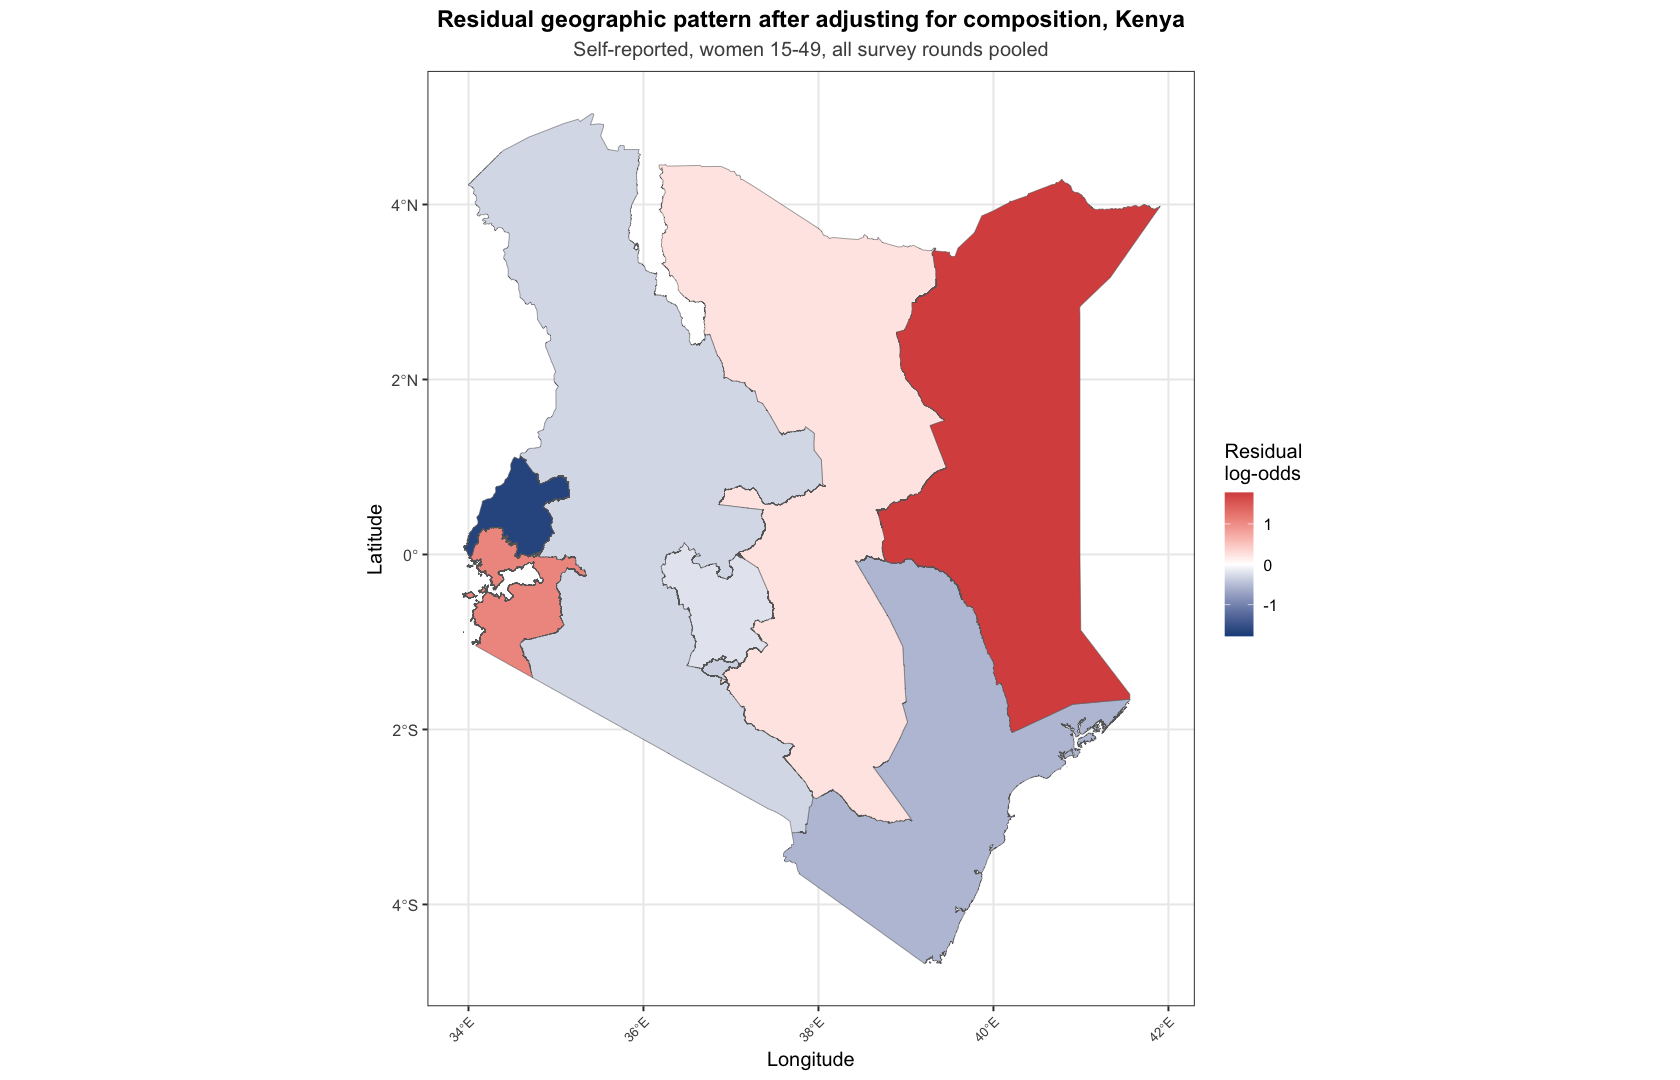

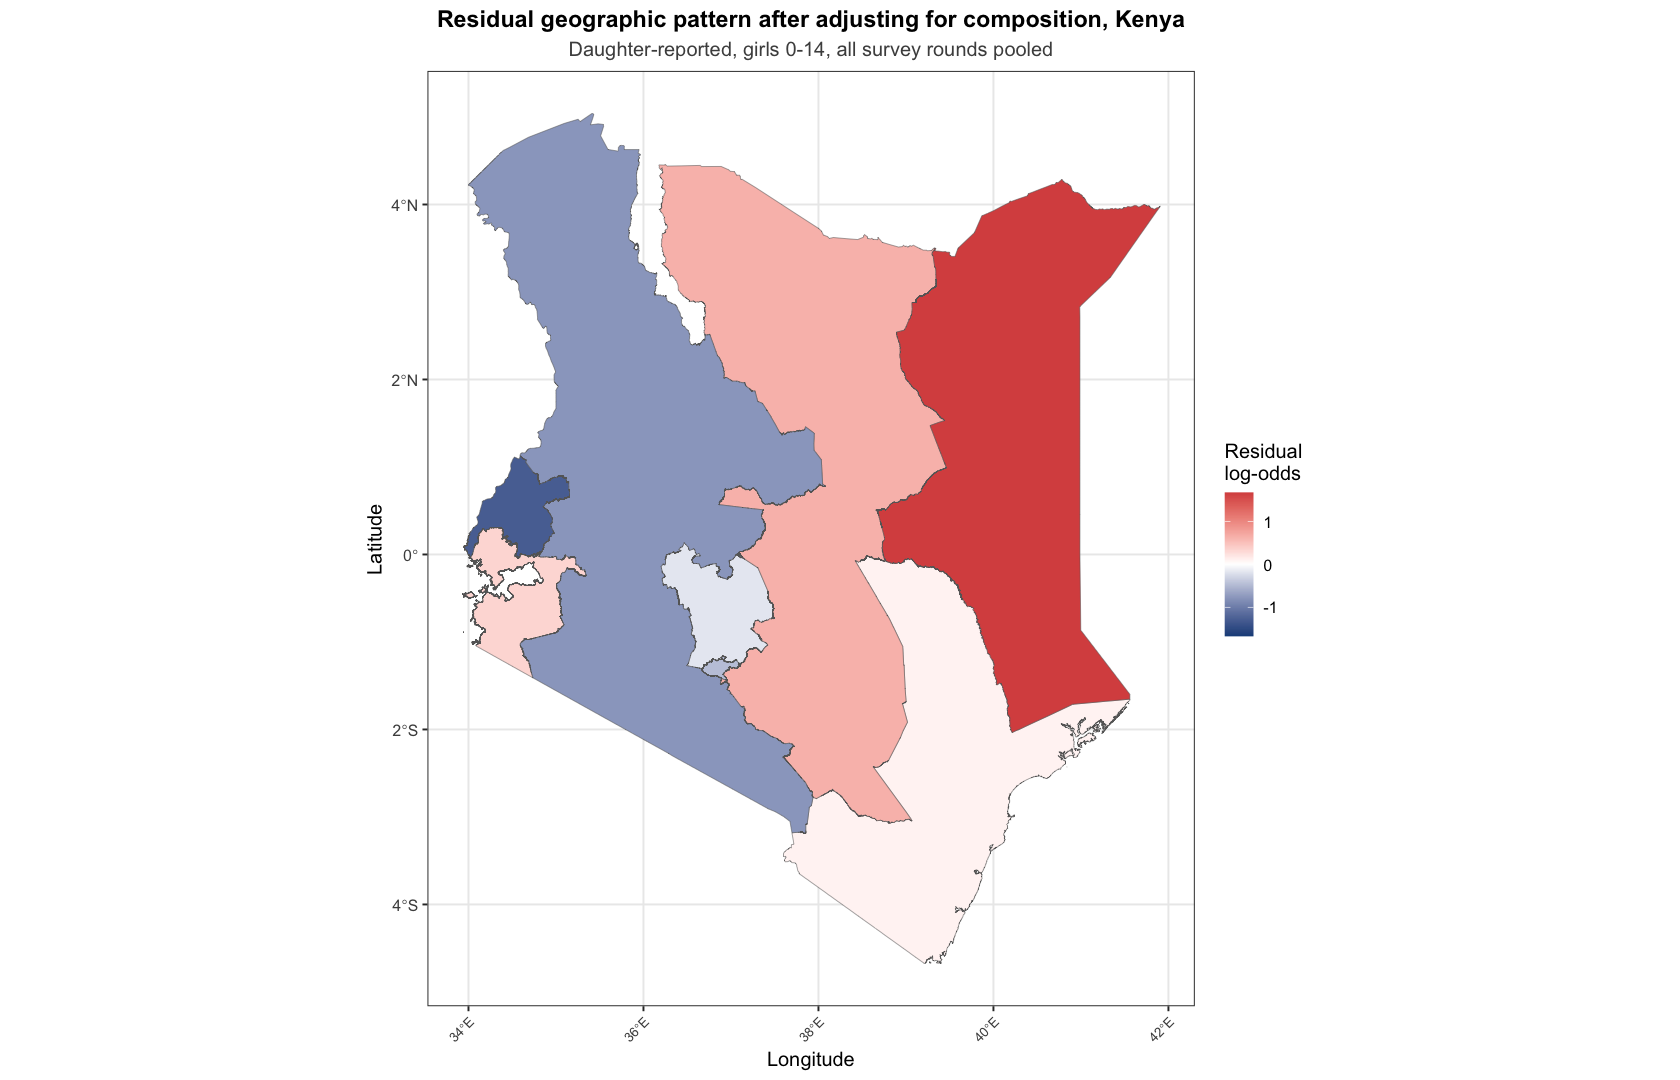

In [11]:
readr::write_csv(dplyr::bind_rows(model_self$residual |> dplyr::mutate(population = "Women 15-49"),
                                  model_daughter$residual |> dplyr::mutate(population = "Girls 0-14")),
                 file.path(dirs$adjusted, paste0(country_iso3, "_prevalence_residual_spatial.csv")))
residual_self_map <- residual_map(model_self$residual, paste("Residual geographic pattern after adjusting for composition,", country_name),
                                  "Self-reported, women 15-49, all survey rounds pooled")
residual_daughter_map <- residual_map(model_daughter$residual, paste("Residual geographic pattern after adjusting for composition,", country_name),
                                      "Daughter-reported, girls 0-14, all survey rounds pooled")
print(residual_self_map); print(residual_daughter_map)
ggplot2::ggsave(file.path(dirs$adjusted, paste0(country_iso3, "_prevalence_residual_map_self.png")), residual_self_map, width = 9, height = 8, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(dirs$adjusted, paste0(country_iso3, "_prevalence_residual_map_daughter.png")), residual_daughter_map, width = 9, height = 8, dpi = 300, bg = "white")

## 7. Trends

(1) National prevalence by survey year, design-based and model-based; (2) prevalence by
birth cohort from the pooled model; (3) design-based prevalence by single birth year.

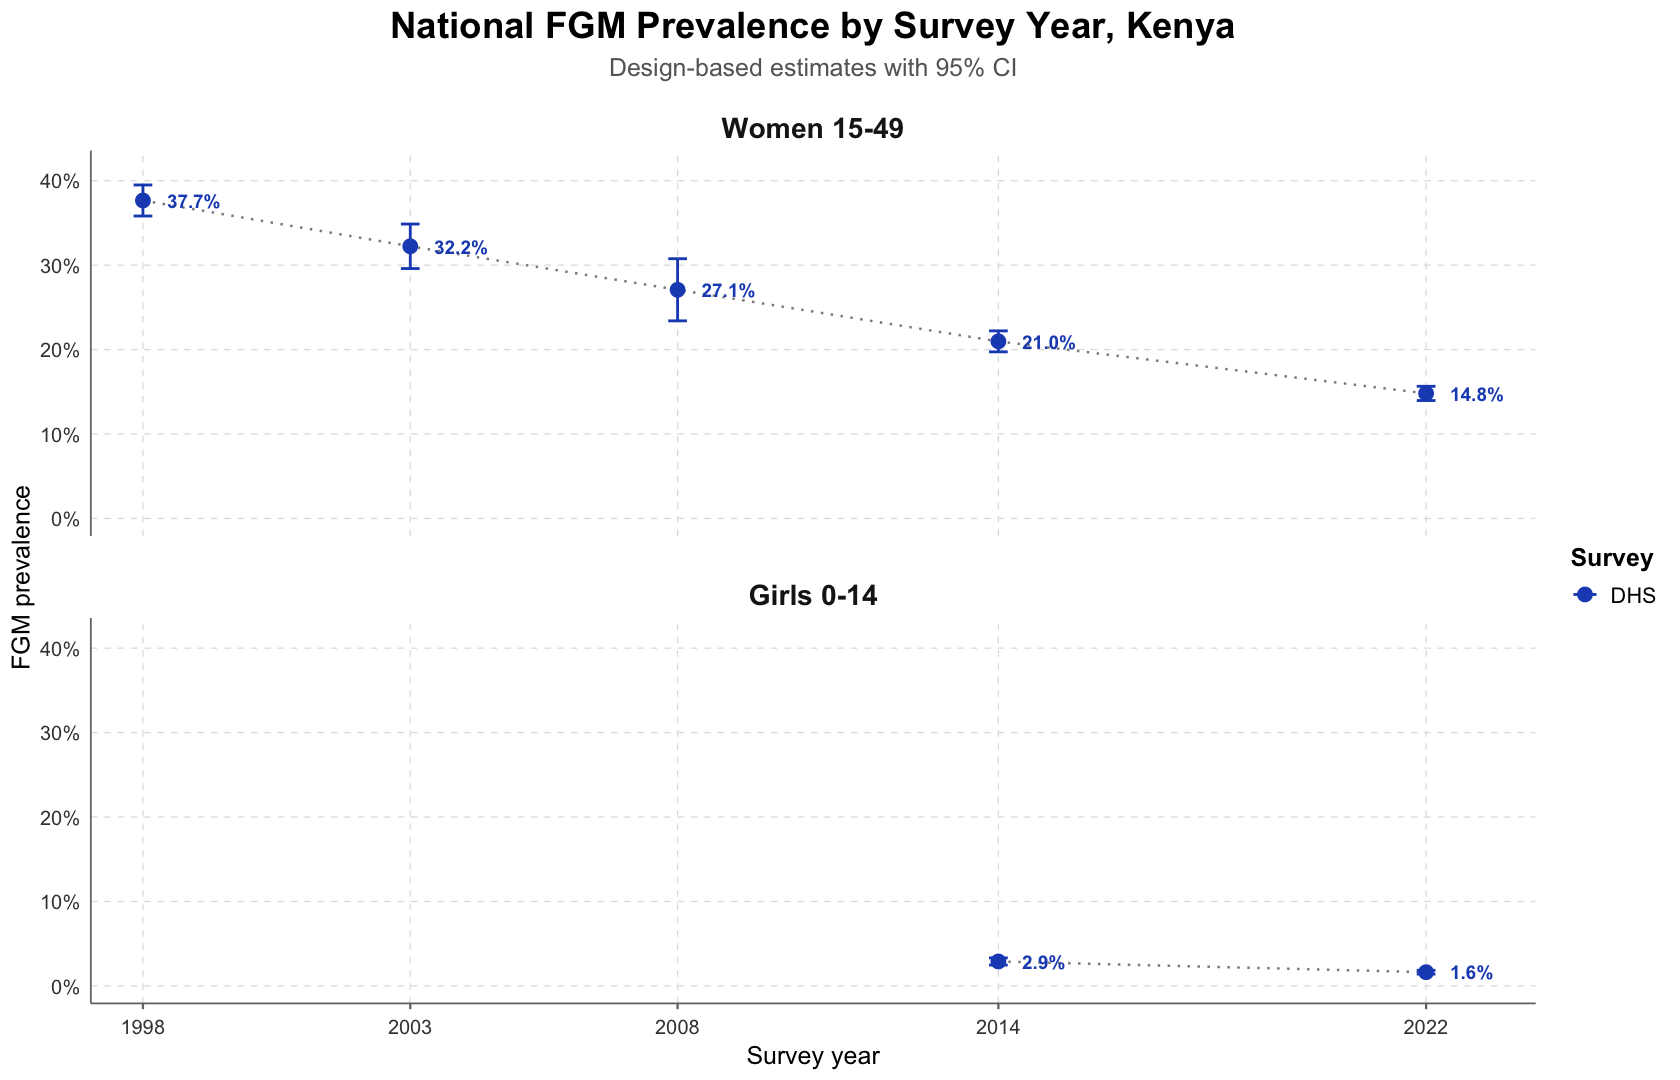

In [12]:
national_trend <- dplyr::bind_rows(
  national_direct |> dplyr::transmute(survey_id, population, estimate = direct, lower_ci, upper_ci, method = "Design-based direct"),
  dplyr::bind_rows(model_self$survey |> dplyr::mutate(population = "Women 15-49"),
                   model_daughter$survey |> dplyr::mutate(population = "Girls 0-14")) |>
    dplyr::transmute(survey_id, population, estimate, lower_ci, upper_ci, method = "Covariate-adjusted model")
) |>
  dplyr::left_join(survey_years |> dplyr::mutate(survey_id = as.character(survey_id)), by = "survey_id") |>
  dplyr::mutate(population = factor(population, levels = c("Women 15-49", "Girls 0-14")))
readr::write_csv(national_trend, file.path(dirs$trends, paste0(country_iso3, "_prevalence_national_by_round.csv")))
survey_colours <- c(DHS = "#1E4FBF", MICS = "#D7301F")
direct_trend <- national_trend |> dplyr::filter(method == "Design-based direct")
national_trend_plot <- ggplot2::ggplot(direct_trend, ggplot2::aes(round_year, estimate, color = survey_type)) +
  ggplot2::geom_line(ggplot2::aes(group = 1), color = "grey55", linetype = "dotted", linewidth = 0.7) +
  ggplot2::geom_errorbar(ggplot2::aes(ymin = lower_ci, ymax = upper_ci), width = 0.35, linewidth = 0.8) +
  ggplot2::geom_point(size = 3.6) +
  ggplot2::geom_text(ggplot2::aes(label = scales::percent(estimate, accuracy = 0.1)), nudge_x = 0.45, hjust = 0,
                     fontface = "bold", size = 4, show.legend = FALSE) +
  ggplot2::facet_wrap(~population, ncol = 1) +
  ggplot2::scale_color_manual(values = survey_colours, name = "Survey") +
  ggplot2::scale_x_continuous(breaks = sort(unique(direct_trend$round_year)), expand = ggplot2::expansion(add = c(0.8, 1.6))) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), breaks = seq(0, 1, by = 0.1),
                              limits = c(0, max(0.30, max(direct_trend$upper_ci) + 0.02))) +
  ggplot2::labs(title = paste("National FGM Prevalence by Survey Year,", country_name),
                subtitle = "Design-based estimates with 95% CI", x = "Survey year", y = "FGM prevalence") +
  ggplot2::theme_minimal(base_size = 14) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 22, hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(size = 15, hjust = 0.5, color = "grey40", margin = ggplot2::margin(b = 10)),
                 strip.text = ggplot2::element_text(face = "bold", size = 17, margin = ggplot2::margin(t = 10, b = 6)),
                 strip.background = ggplot2::element_blank(),
                 panel.grid.major = ggplot2::element_line(color = "grey88", linetype = "dashed", linewidth = 0.35),
                 panel.grid.minor = ggplot2::element_blank(),
                 axis.line = ggplot2::element_line(color = "grey45", linewidth = 0.5),
                 axis.ticks.x = ggplot2::element_line(color = "grey45"),
                 axis.title = ggplot2::element_text(size = 15), axis.text = ggplot2::element_text(size = 12, color = "grey25"),
                 legend.title = ggplot2::element_text(face = "bold", size = 15), legend.text = ggplot2::element_text(size = 13),
                 panel.spacing.y = grid::unit(1.2, "lines"))
print(national_trend_plot)
ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_prevalence_national_by_round.png")), national_trend_plot,
                width = 13, height = 9, dpi = 300, bg = "white")

Warning message:
“The `label.size` argument of `geom_label()` is deprecated as of ggplot2 3.5.0.
ℹ Please use the `linewidth` argument instead.”


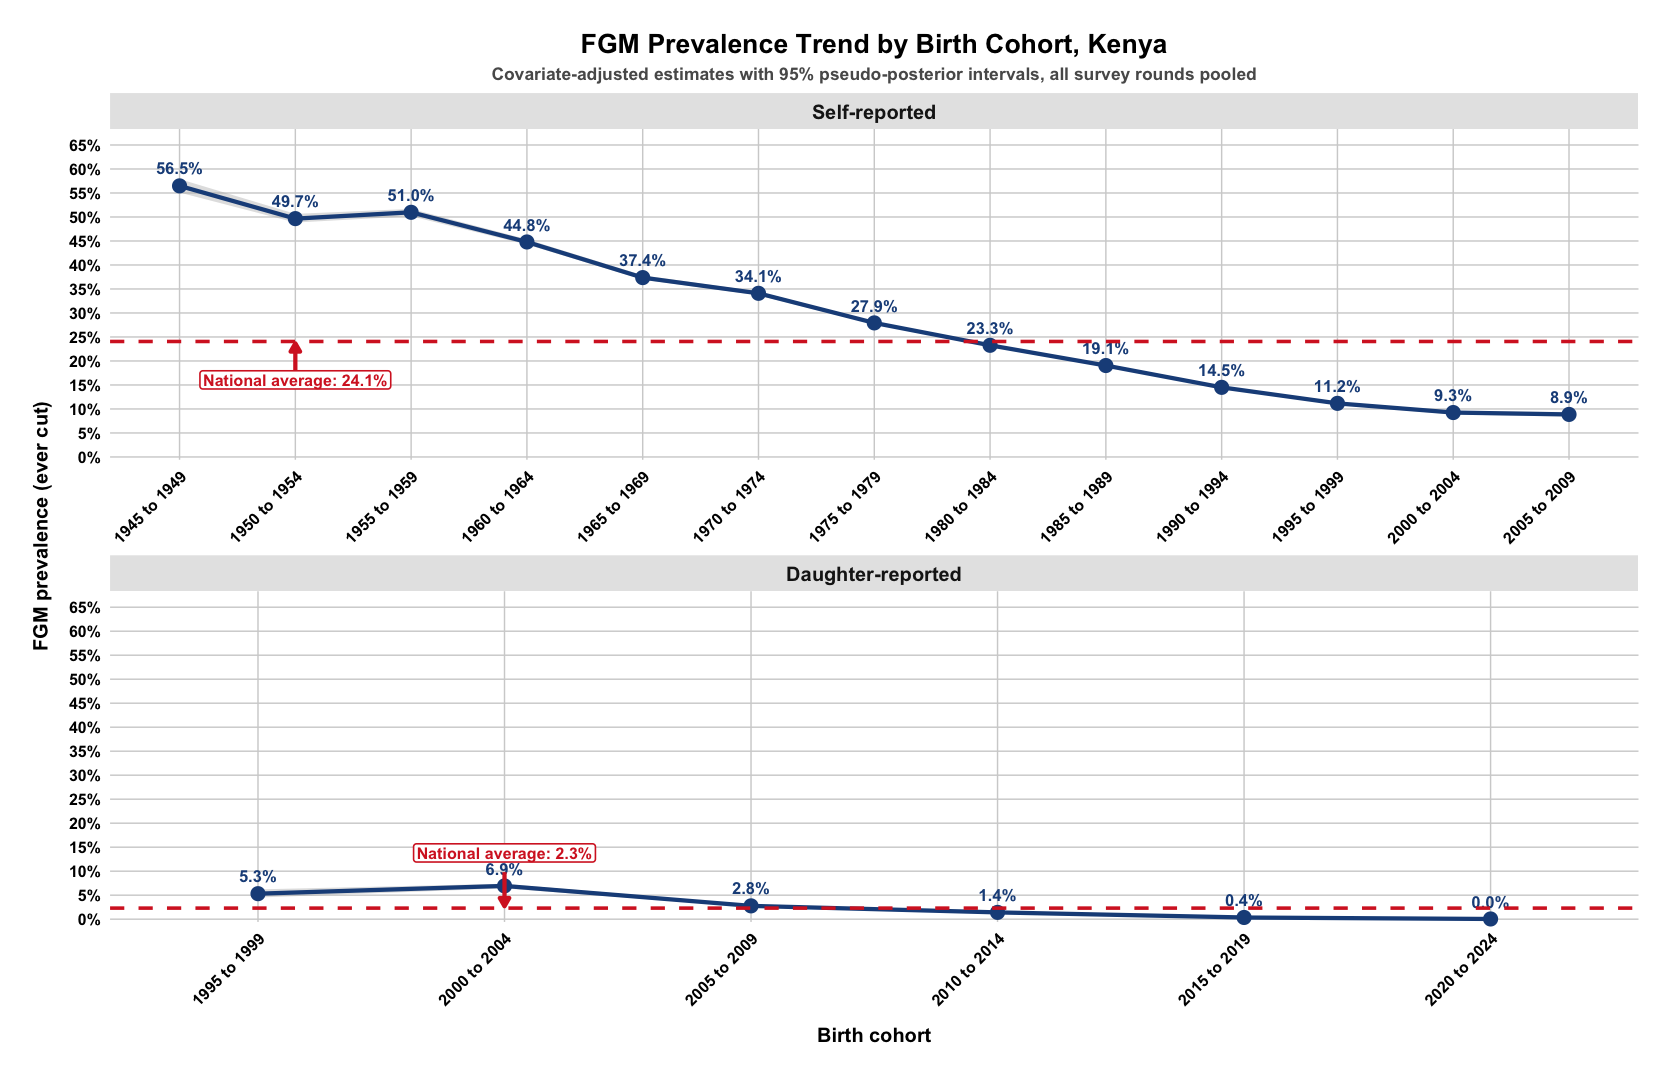

In [13]:
adjusted_prevalence_trend <- dplyr::bind_rows(model_self$cohort |> dplyr::mutate(population = "Women 15-49"),
                                              model_daughter$cohort |> dplyr::mutate(population = "Girls 0-14")) |>
  dplyr::filter(n_unweighted >= minimum_cohort_cell_n) |>
  dplyr::rename(adjusted_prevalence = estimate) |>
  dplyr::mutate(population = factor(population, levels = c("Women 15-49", "Girls 0-14")))
# V1 layout: facet labels by reporting source, national average with a labelled arrow.
adjusted_prevalence_trend <- adjusted_prevalence_trend |>
  dplyr::mutate(record_type = factor(dplyr::if_else(population == "Women 15-49", "Self-reported", "Daughter-reported"),
                                     levels = c("Self-reported", "Daughter-reported")))
cohort_national_average <- adjusted_prevalence_trend |> dplyr::group_by(record_type) |>
  dplyr::summarise(national_average = stats::weighted.mean(adjusted_prevalence, sum_weight), .groups = "drop")
readr::write_csv(adjusted_prevalence_trend, file.path(dirs$trends, paste0(country_iso3, "_prevalence_trend_by_cohort.csv")))
readr::write_csv(cohort_national_average, file.path(dirs$trends, paste0(country_iso3, "_prevalence_national_average.csv")))

# Annotation at the second cohort: label below the line for women, above it for girls.
annotations <- adjusted_prevalence_trend |>
  dplyr::arrange(record_type, birth_cohort) |>
  dplyr::group_by(record_type) |> dplyr::slice(min(2L, dplyr::n())) |> dplyr::ungroup() |>
  dplyr::select(record_type, birth_cohort) |>
  dplyr::left_join(cohort_national_average, by = "record_type") |>
  dplyr::mutate(label = paste0("National average: ", scales::percent(national_average, accuracy = 0.1)),
                label_y = dplyr::if_else(record_type == "Self-reported", pmax(national_average - 0.08, 0.025), national_average + 0.115),
                arrow_start = dplyr::if_else(record_type == "Self-reported", label_y + 0.018, label_y - 0.040),
                arrow_end = dplyr::if_else(record_type == "Self-reported", national_average - 0.004, national_average + 0.004))

cohort_trend_plot <- ggplot2::ggplot(adjusted_prevalence_trend, ggplot2::aes(birth_cohort, adjusted_prevalence)) +
  ggplot2::geom_ribbon(ggplot2::aes(ymin = lower_ci, ymax = upper_ci, group = 1), fill = "grey70", alpha = 0.40) +
  ggplot2::geom_line(ggplot2::aes(group = 1), color = "#1D4E89", linewidth = 1.2) +
  ggplot2::geom_point(color = "#1D4E89", fill = "#1D4E89", shape = 21, size = 3.2, stroke = 0.8) +
  ggplot2::geom_text(ggplot2::aes(label = scales::percent(adjusted_prevalence, accuracy = 0.1)),
                     color = "#1D4E89", fontface = "bold", size = 3.5, vjust = -1) +
  ggplot2::geom_hline(data = cohort_national_average, ggplot2::aes(yintercept = national_average),
                      color = "#D62728", linewidth = 1, linetype = "dashed") +
  ggplot2::geom_segment(data = annotations, ggplot2::aes(x = birth_cohort, xend = birth_cohort, y = arrow_start, yend = arrow_end),
                        inherit.aes = FALSE, color = "#D62728", linewidth = 1.2,
                        arrow = grid::arrow(type = "closed", length = grid::unit(0.20, "cm"))) +
  ggplot2::geom_label(data = annotations, ggplot2::aes(x = birth_cohort, y = label_y, label = label), inherit.aes = FALSE,
                      color = "#D62728", fill = "white", fontface = "bold", size = 3.4, label.size = 0.45,
                      label.padding = grid::unit(0.16, "lines")) +
  ggplot2::facet_wrap(~record_type, ncol = 1, scales = "free_x") +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), breaks = scales::breaks_width(0.05),
                              limits = c(0, NA), expand = ggplot2::expansion(mult = c(0.01, 0.18))) +
  ggplot2::labs(title = paste("FGM Prevalence Trend by Birth Cohort,", country_name),
                subtitle = "Covariate-adjusted estimates with 95% pseudo-posterior intervals, all survey rounds pooled",
                x = "Birth cohort", y = "FGM prevalence (ever cut)") +
  ggplot2::coord_cartesian(clip = "off") +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(text = ggplot2::element_text(face = "bold", color = "black"),
                 plot.title = ggplot2::element_text(face = "bold", size = 16, hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(face = "bold", size = 10.5, hjust = 0.5, color = "grey35"),
                 axis.title.x = ggplot2::element_text(face = "bold", size = 12, margin = ggplot2::margin(t = 12)),
                 axis.title.y = ggplot2::element_text(face = "bold", size = 12, margin = ggplot2::margin(r = 10)),
                 axis.text = ggplot2::element_text(face = "bold", color = "black"),
                 axis.text.x = ggplot2::element_text(face = "bold", angle = 45, hjust = 1),
                 strip.text = ggplot2::element_text(face = "bold", size = 12),
                 strip.background = ggplot2::element_rect(fill = "grey90", color = NA),
                 panel.grid.major = ggplot2::element_line(color = "grey82", linewidth = 0.4),
                 panel.grid.minor = ggplot2::element_blank(),
                 plot.margin = ggplot2::margin(20, 25, 20, 20))
print(cohort_trend_plot)
ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_prevalence_trend_by_cohort.png")), cohort_trend_plot,
                width = 10, height = 9, dpi = 300, bg = "white")

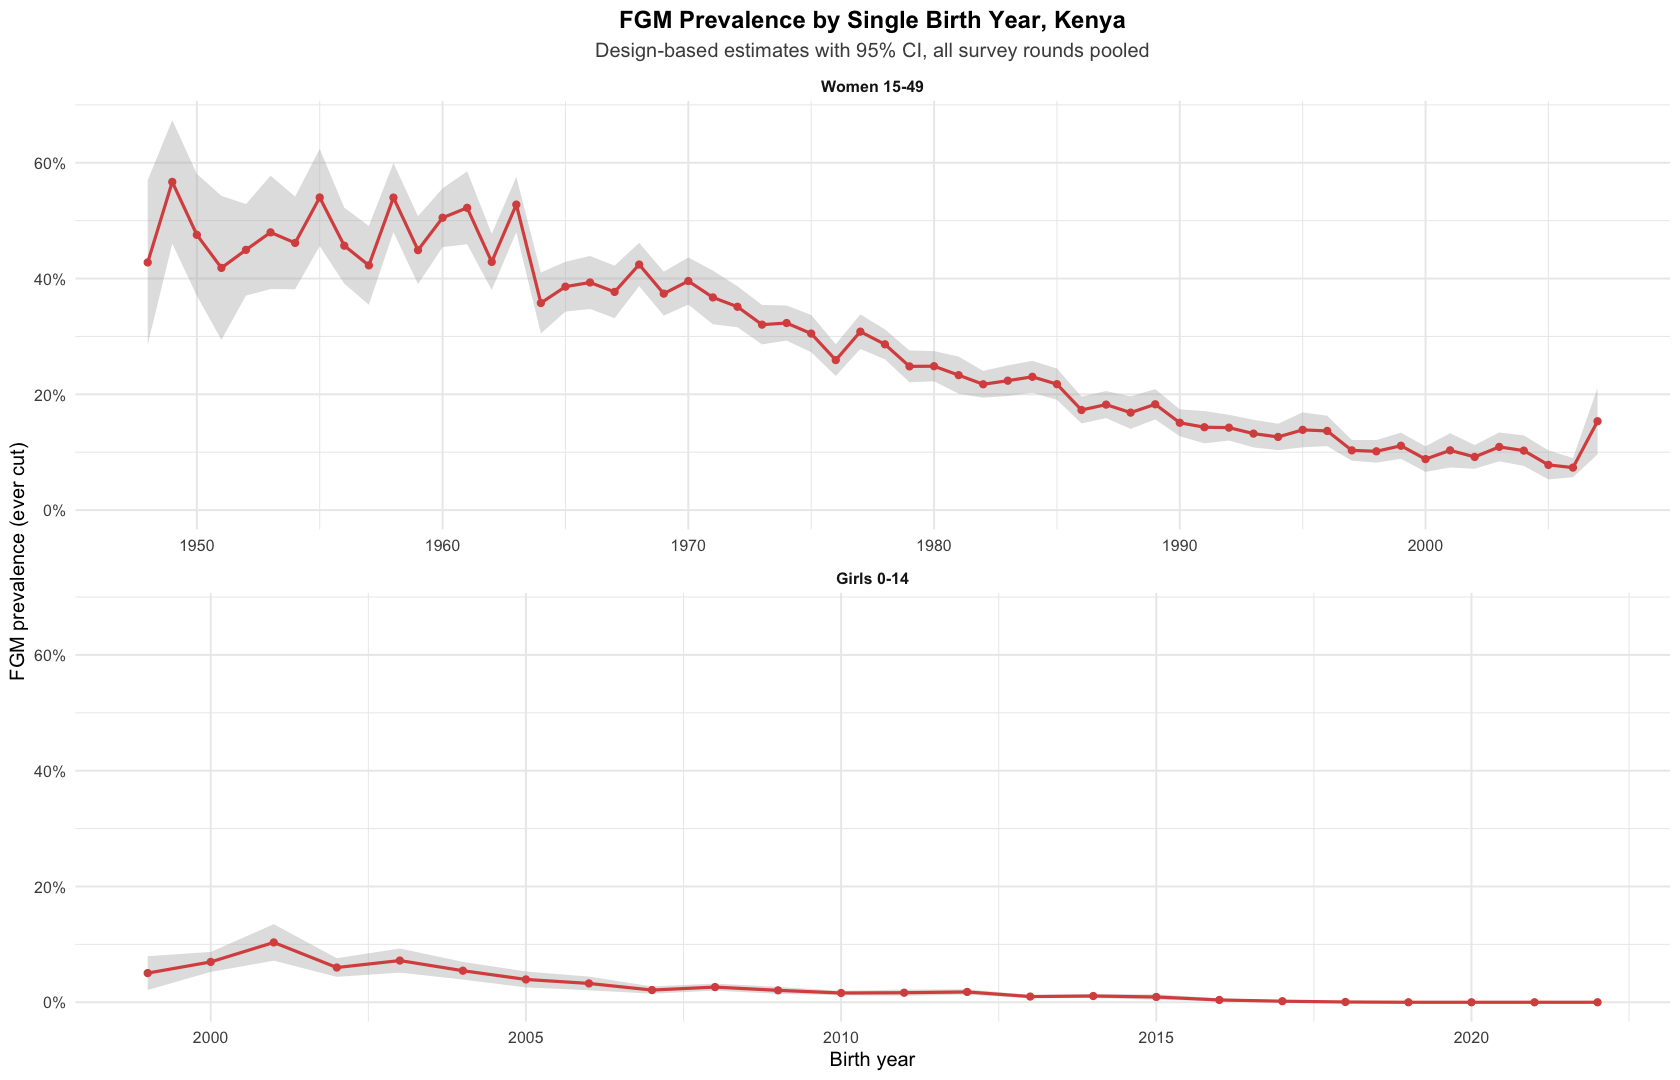

In [14]:
year_estimates <- function(data, outcome, population) {
  pooled_direct(data |> dplyr::filter(!is.na(birth_year)), outcome, "birth_year") |>
    dplyr::rename(prevalence = direct) |> dplyr::mutate(population = population)
}
prevalence_by_year <- dplyr::bind_rows(year_estimates(women, "fgm_self", "Women 15-49"),
                                       year_estimates(daughters, "fgm_daughter", "Girls 0-14")) |>
  dplyr::mutate(population = factor(population, levels = c("Women 15-49", "Girls 0-14")))
readr::write_csv(prevalence_by_year, file.path(dirs$trends, paste0(country_iso3, "_prevalence_by_birth_year.csv")))
prevalence_year_plot <- ggplot2::ggplot(prevalence_by_year, ggplot2::aes(birth_year, prevalence)) +
  ggplot2::geom_ribbon(ggplot2::aes(ymin = lower_ci, ymax = upper_ci), fill = "grey70", alpha = 0.4) +
  ggplot2::geom_line(color = "#D9534F", linewidth = 0.9) + ggplot2::geom_point(color = "#D9534F", size = 1.6) +
  ggplot2::facet_wrap(~population, ncol = 1, scales = "free_x") +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, NA)) +
  ggplot2::labs(title = paste("FGM Prevalence by Single Birth Year,", country_name),
                subtitle = "Design-based estimates with 95% CI, all survey rounds pooled", x = "Birth year", y = "FGM prevalence (ever cut)") +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5), plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                 strip.text = ggplot2::element_text(face = "bold"))
print(prevalence_year_plot)
ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_prevalence_by_birth_year.png")), prevalence_year_plot, width = 11, height = 8, dpi = 300, bg = "white")

## 8. Validation

Pooled model-based region estimates against the pooled design-based direct estimates.

In [15]:
validation <- dplyr::bind_rows(adjusted_self |> dplyr::mutate(population = "Women 15-49"),
                               adjusted_daughter |> dplyr::mutate(population = "Girls 0-14")) |>
  dplyr::group_by(population) |>
  dplyr::summarise(regions = dplyr::n(), correlation = stats::cor(model_assisted_prevalence, design_based_direct),
                   mean_abs_diff_pp = 100 * mean(abs(model_assisted_prevalence - design_based_direct)),
                   max_abs_diff_pp = 100 * max(abs(model_assisted_prevalence - design_based_direct)), .groups = "drop")
readr::write_csv(validation, file.path(dirs$validation, paste0(country_iso3, "_prevalence_model_vs_direct.csv")))
IRdisplay::display(as.data.frame(validation |> dplyr::mutate(dplyr::across(where(is.numeric), ~ round(.x, 3)))))

population,regions,correlation,mean_abs_diff_pp,max_abs_diff_pp
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Girls 0-14,8,1,0.085,0.246
Women 15-49,8,1,0.049,0.222


## Results

Prevalence pools all five DHS rounds: 56,116 women aged 15–49 with a known FGM status and 26,714
daughters aged 0–14 from DHS 2014 and 2022. Kenya has no national MICS.

**1. National prevalence has fallen by more than half.** Among women 15–49 it fell from 37.7% in
DHS 1998 to 32.2% (2003), 27.1% (2008–09), 21.0% (2014) and 14.8% (2022). Among girls 0–14 it was
2.9% in 2014 and 1.6% in 2022. These figures reproduce the official DHS reports.

**2. North Eastern stands apart.** Pooling all rounds, model-based prevalence among women is 95.0%
in North Eastern, then 34.7% in Nyanza, 30.5% in Rift Valley and 29.3% in Eastern, and 1.7% in
Western. Among girls it is 35.4% in North Eastern and 4.0% in Nyanza, and under 2% elsewhere.

**3. Counties (DHS 2014 and 2022).** In 2022 prevalence among women is highest in Wajir (96.3%),
Mandera (95.9%), Marsabit (82.9%), Garissa (80.4%), Kisii (76.6%), Nyamira (74.1%) and Samburu
(73.3%). Among girls it is highest in Wajir (42.4%), Mandera (27.4%) and Garissa (23.9%).

**4. Prevalence has declined across birth cohorts.** Among women it falls from 56.5% for those
born in 1945–49 to 34.1% (1970–74), 19.1% (1985–89) and 8.9% (2005–09); the pooled average is 24.1%.

**5. Composition.** Relative to Kalenjin women, the odds of being cut are much higher among Kisii
(20.5), Maasai (10.0) and Somali (5.9) women and much lower among Luo, Luhya and Mijikenda/Swahili
women. Muslim women (4.8) and the poorest (1.8) have higher odds; secondary education (0.24) and
urban residence (0.77) lower odds.

**6. Consistency check.** The pooled model reproduces the direct province estimates (within 0.25
points). A weakly informative prior on the model coefficients keeps estimates stable for groups
with almost no cut girls.

**7. Subnational MICS (section 8A).** MICS and DHS agree for the same areas: Nyanza 36.5% (MICS
2011) against 32.4% (DHS 2014); Bungoma 2.1% against 1.2%, Kakamega 1.2% against 0.8% and Turkana
3.2% against 3.7% (MICS 2013–14 against DHS 2014). None of the differences is significant.

## Notes

- Outcome: "ever cut" prevalence (SDG 5.3.2), not the age-specific risk of the risk notebook.
- Maps pool all rounds. The pooled region estimate averages over every respondent interviewed
  in the region across 1998–2022, with weights rescaled to mean one within each survey, so it
  describes the period as a whole rather than one year; cohort maps show change over time.
- Daughters' prevalence is not lifetime risk: many girls are not yet past the ages at which
  cutting occurs.
- Model-based estimates average predictions over each region's observed weighted composition
  and use a survey-weighted pseudo-likelihood; their intervals do not fully reproduce the
  clustered design. The direct estimates remain the design-based benchmark.

## 8A. Comparison with Kenya's subnational MICS

Prevalence among women 15–49 in each MICS area against DHS for the same area: Bungoma, Kakamega
and Turkana MICS 2013–14 against DHS 2014 for the same county; Nyanza MICS 2011 against DHS
2008–09 and 2014 for Nyanza province; Mombasa informal settlements MICS 2009 against DHS 2014 for
the whole of Mombasa county (indicative only, since informal settlements are a subset).

comparison,area,source,prevalence,lower_ci,upper_ci,n
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>
MICS 2009 Mombasa informal settlements,MOMBASA,MICS 2009 Mombasa informal settlements,12.4,10.0,14.8,821
MICS 2009 Mombasa informal settlements,MOMBASA,DHS 2014,7.4,2.8,12.1,272
MICS 2011 Nyanza,NYANZA,MICS 2011 Nyanza,36.5,30.9,42.0,5901
MICS 2011 Nyanza,NYANZA,DHS 2008,33.9,19.4,48.4,1315
MICS 2011 Nyanza,NYANZA,DHS 2014,32.4,27.7,37.2,2014
MICS 2013-14 Bungoma,BUNGOMA,MICS 2013-14 Bungoma,2.1,1.0,3.2,1213
MICS 2013-14 Bungoma,BUNGOMA,DHS 2014,1.2,0.0,2.3,389
MICS 2013-14 Kakamega,KAKAMEGA,MICS 2013-14 Kakamega,1.2,0.5,1.8,998
MICS 2013-14 Kakamega,KAKAMEGA,DHS 2014,0.8,0.0,1.7,352


comparison,versus,difference,lower,upper,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
MICS 2009 Mombasa informal settlements,DHS 2014,5.0,-0.3,10.2,0.06471458
MICS 2011 Nyanza,DHS 2014,4.1,-3.2,11.4,0.27328608
MICS 2013-14 Bungoma,DHS 2014,0.9,-0.7,2.5,0.26691848
MICS 2013-14 Kakamega,DHS 2014,0.3,-0.8,1.5,0.55045345
MICS 2013-14 Turkana,DHS 2014,-0.5,-7.2,6.2,0.88504285


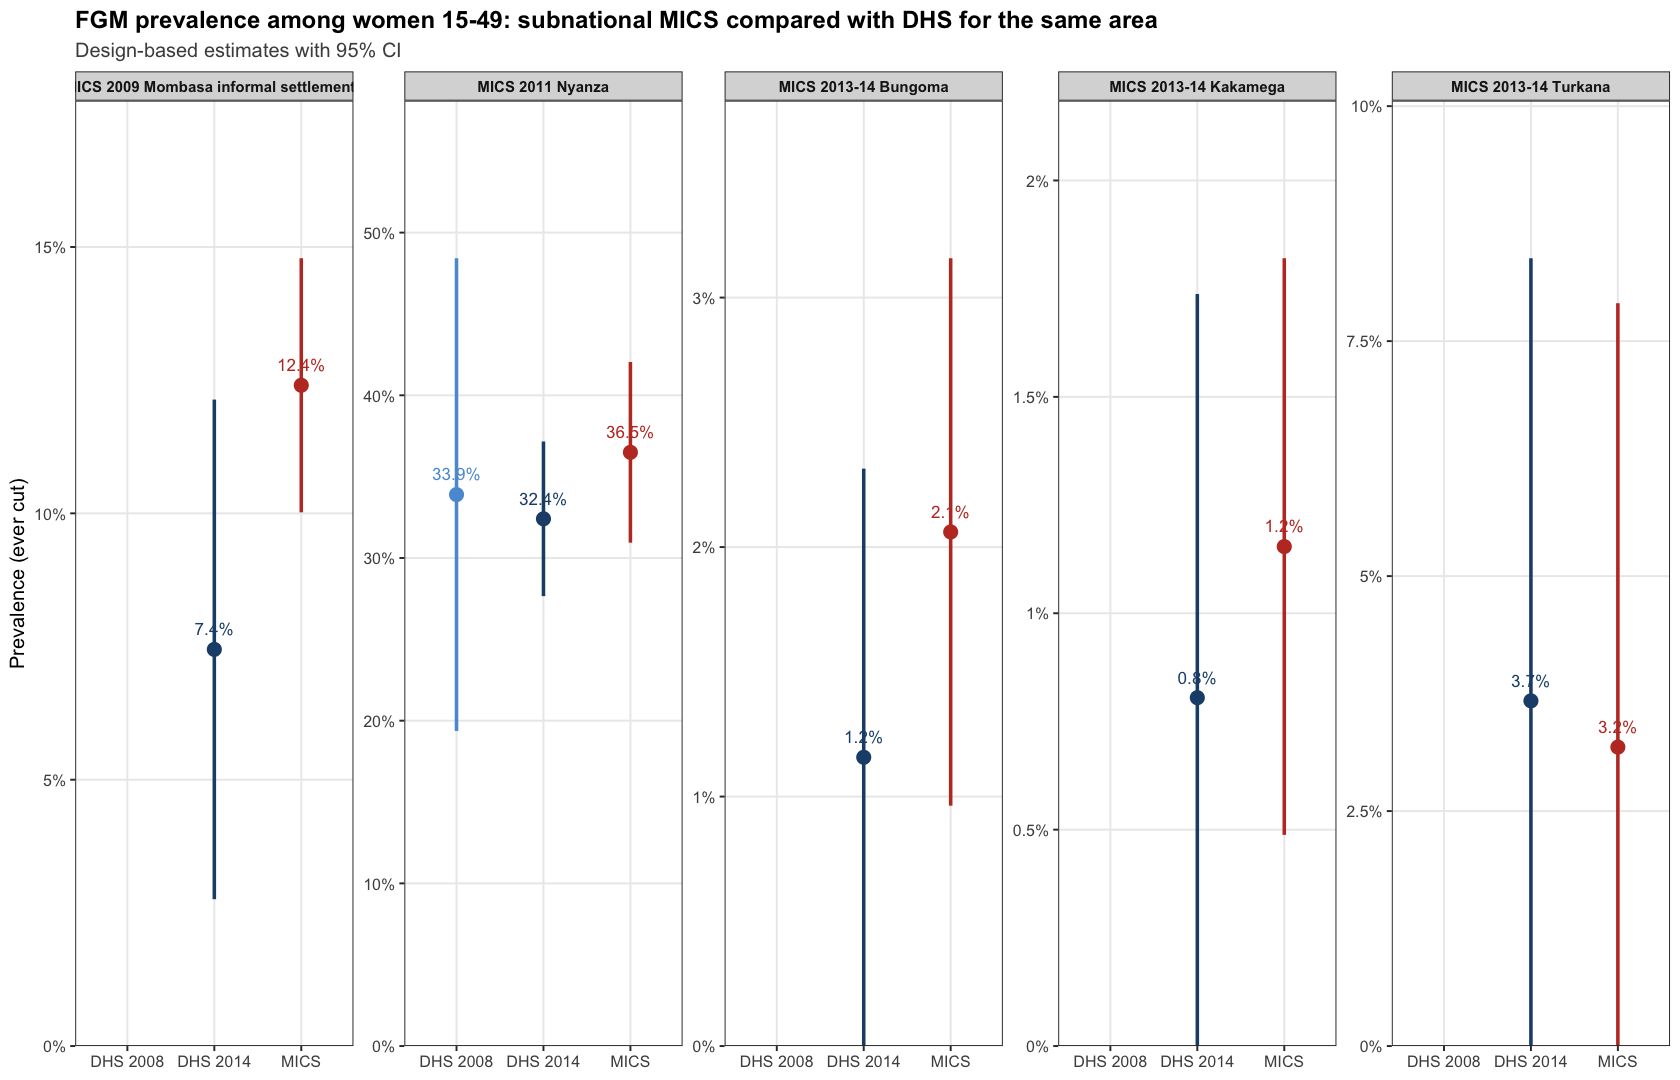

In [16]:
source(file.path(project_root, "00_Pipeline", "mics_core.R"))
source(file.path(project_root, "00_Pipeline", "county_core.R"))
options(survey.lonely.psu = "adjust")
pct1 <- function(x) round(100 * x, 1)
harmonized_path <- file.path(project_root, "02_Data", "processed", country_iso3, "harmonized")
h_women <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_women_all_rounds.rds"))) |>
  dplyr::mutate(fgm_heard = as.numeric(fgm_heard))
mics_women <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_mics_subnational_women.rds")))

mics_out <- file.path(output_dir, "07_MICS_Comparison")
dir.create(mics_out, recursive = TRUE, showWarnings = FALSE)
mics_prev <- mics_vs_dhs(mics_women, h_women, "fgm_status")
mics_prev_diff <- dplyr::bind_rows(lapply(unique(mics_prev$comparison), function(cmp) {
  x <- mics_prev |> dplyr::filter(comparison == cmp)
  m <- x |> dplyr::filter(source == cmp); d <- x |> dplyr::filter(source != cmp) |> dplyr::slice_tail(n = 1)
  diff_test(m, d) |> dplyr::mutate(comparison = cmp, versus = d$source, .before = 1)
})) |> dplyr::mutate(dplyr::across(c(difference, lower, upper), pct1))
mics_prev_table <- mics_prev |> dplyr::transmute(comparison, area, source, prevalence = pct1(estimate), lower_ci = pct1(lower_ci),
                                                 upper_ci = pct1(upper_ci), n)
readr::write_csv(mics_prev_table, file.path(mics_out, paste0(country_iso3, "_mics_prevalence_by_source.csv")))
readr::write_csv(mics_prev_diff, file.path(mics_out, paste0(country_iso3, "_mics_prevalence_difference_test.csv")))
IRdisplay::display(as.data.frame(mics_prev_table)); IRdisplay::display(as.data.frame(mics_prev_diff))

mics_prev_plot <- ggplot2::ggplot(mics_prev |> dplyr::mutate(programme = ifelse(grepl("^MICS", source), "MICS", source)),
                                  ggplot2::aes(programme, 100 * estimate, colour = programme)) +
  ggplot2::geom_pointrange(ggplot2::aes(ymin = 100 * lower_ci, ymax = 100 * upper_ci), size = 0.7, linewidth = 1) +
  ggplot2::geom_text(ggplot2::aes(label = paste0(round(100 * estimate, 1), "%")), vjust = -1.2, size = 3.6, show.legend = FALSE) +
  ggplot2::facet_wrap(~comparison, nrow = 1, scales = "free_y") +
  ggplot2::scale_colour_manual(values = c(MICS = "#C0392B", "DHS 2008" = "#5B9BD5", "DHS 2014" = "#1F4E79"), guide = "none") +
  ggplot2::scale_y_continuous(labels = function(x) paste0(x, "%"), limits = c(0, NA), expand = ggplot2::expansion(mult = c(0, 0.2))) +
  ggplot2::labs(title = "FGM prevalence among women 15-49: subnational MICS compared with DHS for the same area",
                subtitle = "Design-based estimates with 95% CI", x = NULL, y = "Prevalence (ever cut)") +
  ggplot2::theme_bw(base_size = 12) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold"), plot.subtitle = ggplot2::element_text(colour = "grey30"),
                 strip.text = ggplot2::element_text(face = "bold", size = 9), panel.grid.minor = ggplot2::element_blank())
print(mics_prev_plot)
ggplot2::ggsave(file.path(mics_out, paste0(country_iso3, "_mics_prevalence_by_source.png")), mics_prev_plot,
                width = 16, height = 6, dpi = 300, bg = "white")

## 8B. County prevalence (47 counties), DHS 2014 and 2022

Counties are recorded only in DHS 2014 and 2022. Design-based county estimates are smoothed with
an area-level BYM2 model (direct logit estimate with its sampling variance as known precision),
separately for each round, for women 15–49 and girls 0–14.

county,direct,se,n,smoothed,lower_ci,upper_ci,survey_id
<chr>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<chr>
MANDERA,99.7,0.003121470,260,99.5,92.3,100.0,DHS 2014
WAJIR,98.6,0.007887744,244,98.3,95.2,99.4,DHS 2014
GARISSA,95.1,0.019999724,275,94.2,87.8,97.3,DHS 2014
MARSABIT,94.4,0.023759712,269,94.1,87.1,97.4,DHS 2014
KISII,89.6,0.019926943,383,88.9,84.1,92.4,DHS 2014
NYAMIRA,91.3,0.035924827,306,88.7,77.1,94.8,DHS 2014
SAMBURU,79.7,0.039821699,273,78.8,69.8,85.6,DHS 2014
WEST POKOT,71.8,0.048425597,255,70.2,59.8,78.9,DHS 2014
WAJIR,97.2,0.014705624,426,96.3,90.8,98.6,DHS 2022


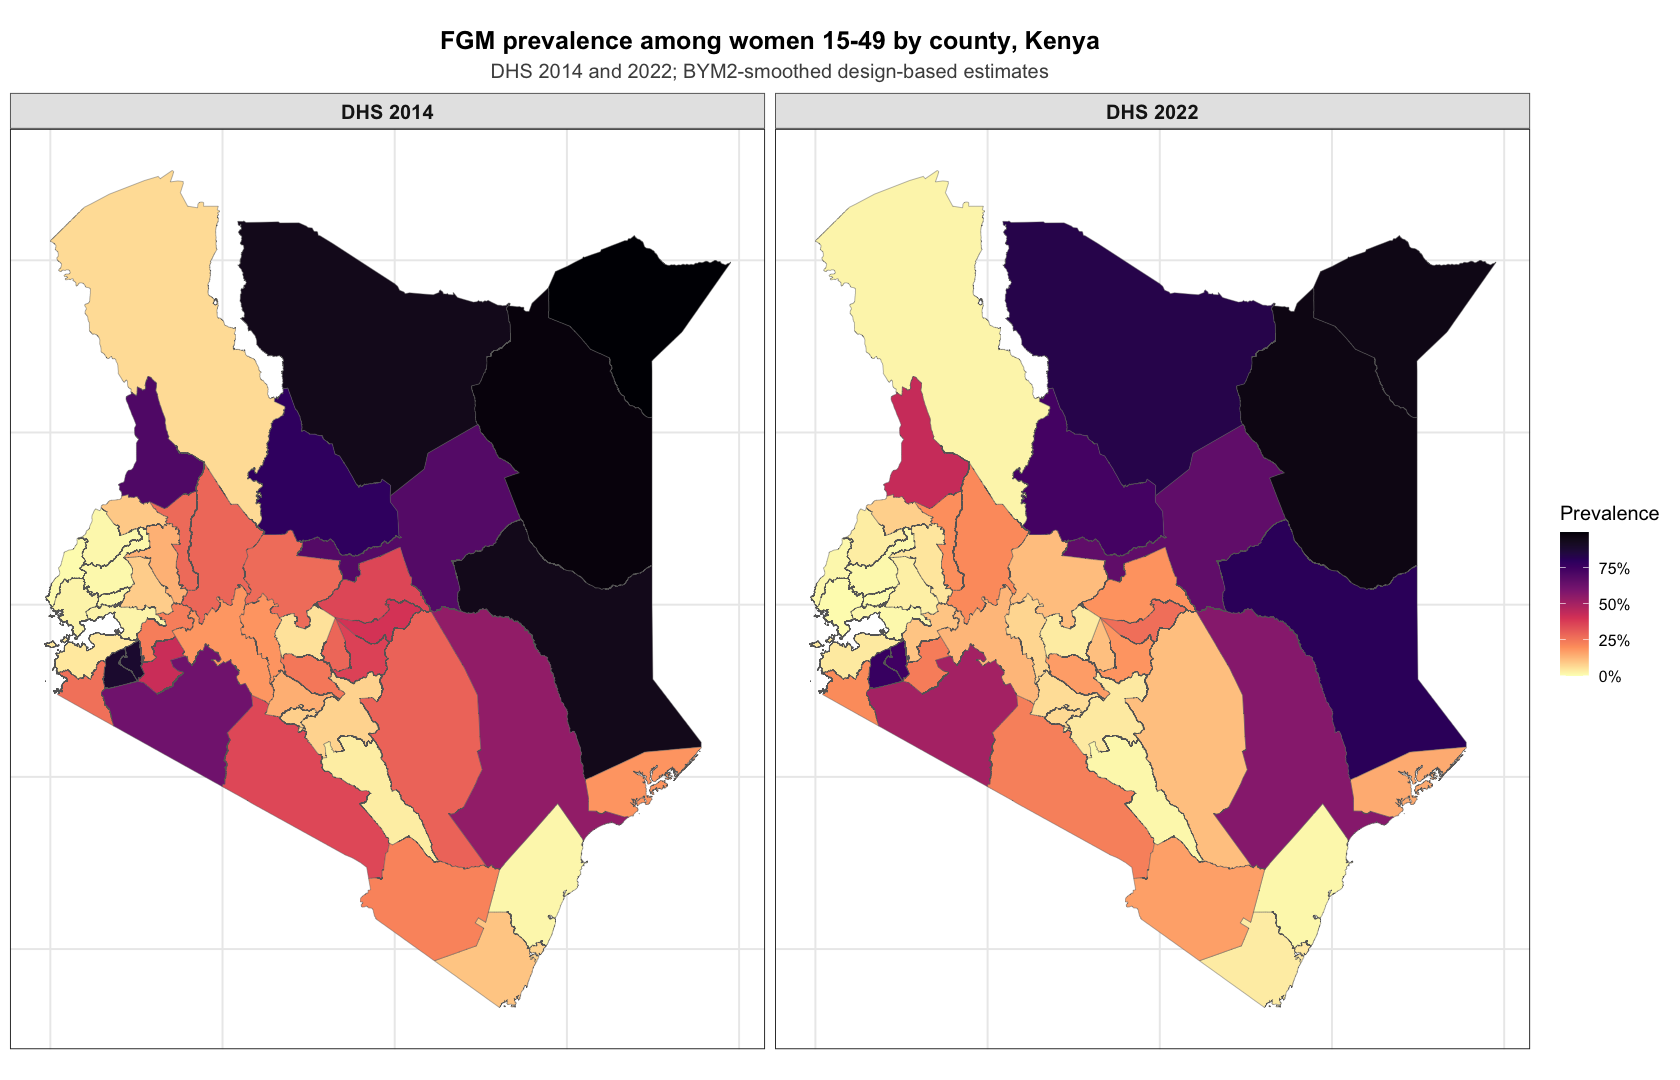

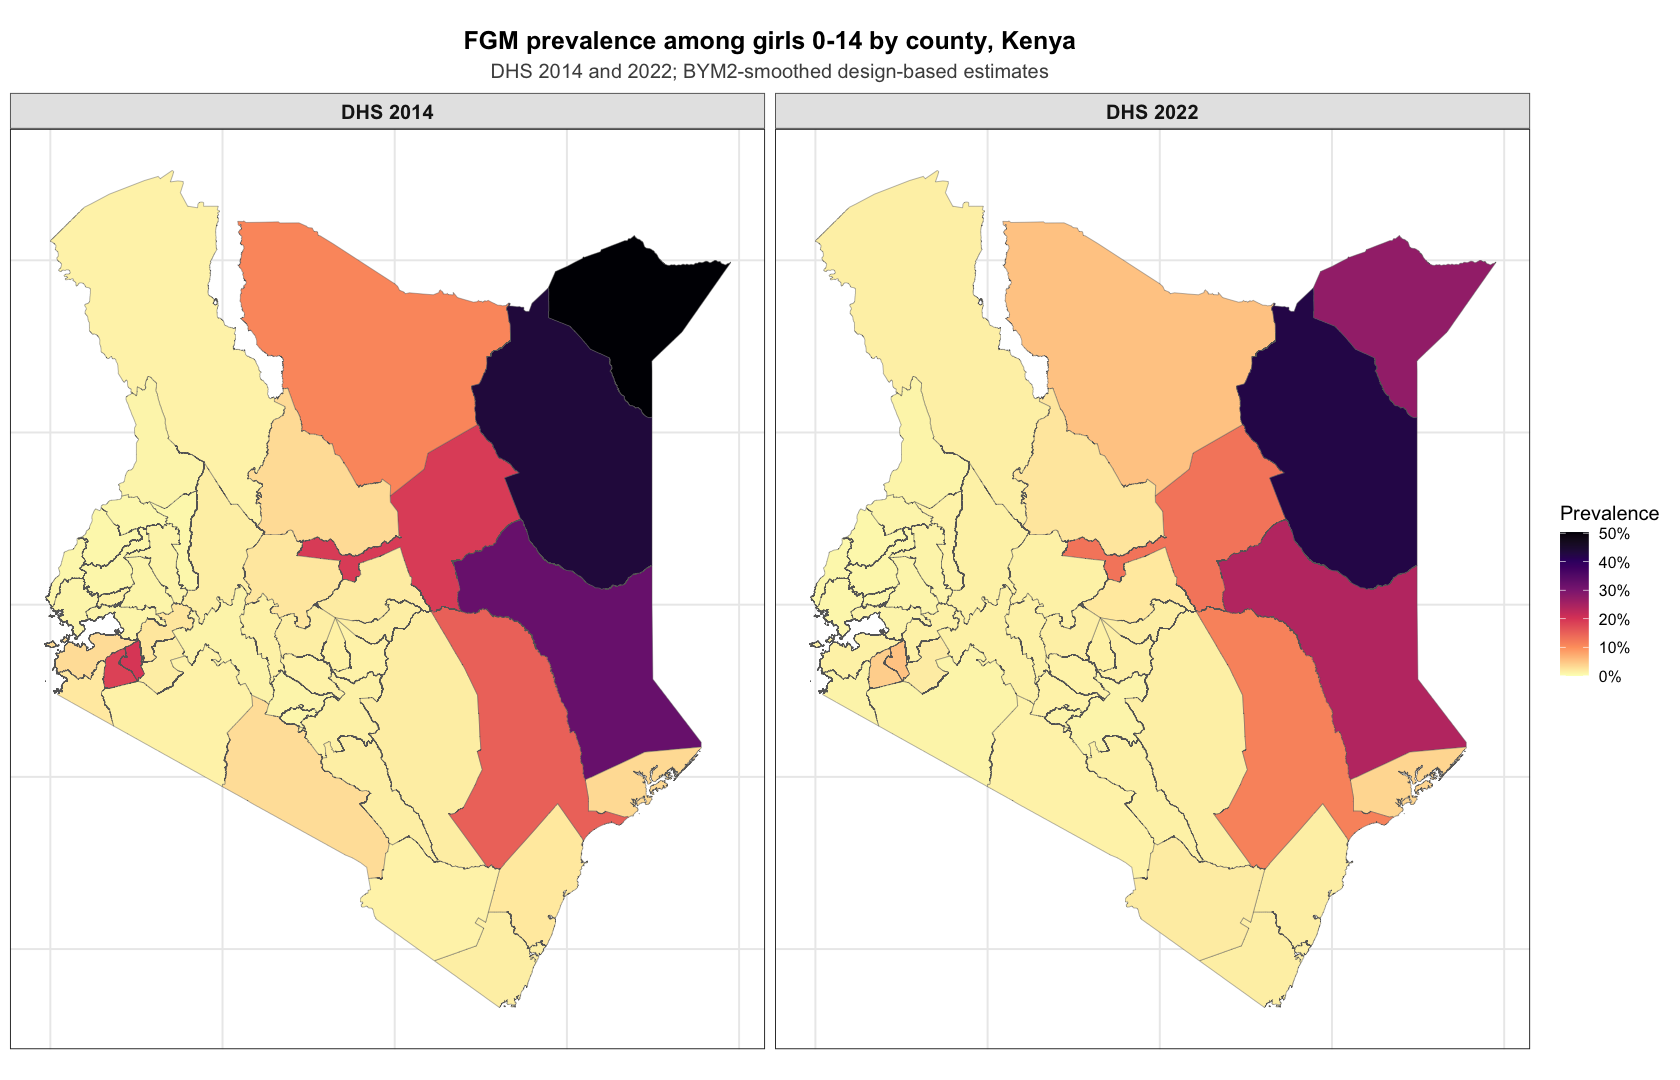

In [17]:
source(file.path(project_root, "00_Pipeline", "mics_core.R"))
source(file.path(project_root, "00_Pipeline", "county_core.R"))
options(survey.lonely.psu = "adjust")
pct1 <- function(x) round(100 * x, 1)
harmonized_path <- file.path(project_root, "02_Data", "processed", country_iso3, "harmonized")
h_women <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_women_all_rounds.rds"))) |>
  dplyr::mutate(fgm_heard = as.numeric(fgm_heard))
mics_women <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_mics_subnational_women.rds")))

county_out <- file.path(output_dir, "08_County_Level")
dir.create(county_out, recursive = TRUE, showWarnings = FALSE)
county_b <- county_boundaries(project_root)
h_daughters <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_daughters_all_rounds.rds")))
county_women <- county_series(h_women, "fgm_status", c("DHS 2014", "DHS 2022"), county_b)
county_girls <- county_series(h_daughters, "daughter_status", c("DHS 2014", "DHS 2022"), county_b)
readr::write_csv(county_women, file.path(county_out, paste0(country_iso3, "_county_prevalence_women.csv")))
readr::write_csv(county_girls, file.path(county_out, paste0(country_iso3, "_county_prevalence_girls.csv")))
IRdisplay::display(as.data.frame(county_women |> dplyr::group_by(survey_id) |> dplyr::slice_max(smoothed, n = 8) |>
  dplyr::mutate(dplyr::across(c(direct, smoothed, lower_ci, upper_ci), pct1))))
for (spec in list(list(county_women, "women 15-49", "women"), list(county_girls, "girls 0-14", "girls"))) {
  p <- county_map(spec[[1]], county_b, paste("FGM prevalence among", spec[[2]], "by county, Kenya"),
                  "DHS 2014 and 2022; BYM2-smoothed design-based estimates", "Prevalence")
  print(p)
  ggplot2::ggsave(file.path(county_out, paste0(country_iso3, "_county_prevalence_", spec[[3]], ".png")), p,
                  width = 13, height = 7, dpi = 300, bg = "white")
}